# IAU Project - Phase 1: Exploratory Analysis and Statistical Testing

The goal of this phase is to explore the provided datasets, identify and address data quality issues, and statistically
examine relationships between selected attributes and the target variable Failure.

## Team Contributions

Dmytro Petrenko 50%

Oleh Serdiukov 50%


In [269]:
from pathlib import Path
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from IPython.display import display, Markdown

DATA = Path("../data")
if not DATA.is_dir():
    DATA = Path("data")
if not DATA.is_dir():
    raise FileNotFoundError("Run from the repository root or notebooks/ with data/ available.")


## 1.1 - Exploratory Data Analysis

### 1.1(A) - Data Structure and Relationships

Inspect the original files, columns and device relationships before any cleaning.
The prediction target is `Failure` in readings.csv. A reading is a measurement
record, not necessarily an independent equipment unit.


In [270]:
file_settings = {
    "readings": "\t",
    "units": ",",
    "gateways": ";",
}

raw_tables = {
    name: pd.read_csv(DATA / f"{name}.csv", sep=separator)
    for name, separator in file_settings.items()
}

readings_raw = raw_tables["readings"]
units_raw = raw_tables["units"]
gateways_raw = raw_tables["gateways"]

#file-level structure
inventory = pd.DataFrame([
    {
        "file": f"{name}.csv",
        "separator": repr(file_settings[name]),
        "size_bytes": (DATA / f"{name}.csv").stat().st_size,
        "rows": len(df),
        "columns": df.shape[1],
        "extra_exact_duplicates": df.duplicated().sum(),
    }
    for name, df in raw_tables.items()
])

display(inventory)

#column-level structure and example records
for name, df in raw_tables.items():
    print(f"\n{name}.csv")

    display(pd.DataFrame({
        "data_type": df.dtypes.astype(str),
        "missing_count": df.isna().sum(),
        "unique_non_missing": df.nunique(),
    }))

    display(df.head(3))

,file,separator,size_bytes,rows,columns,extra_exact_duplicates
0,readings.csv,'\t',1201318,13288,11,196
1,units.csv,"','",148617,2000,9,0
2,gateways.csv,';',1509319,16000,10,0



readings.csv


,data_type,missing_count,unique_non_missing
unitId,str,0,2117
ts_cycle,str,0,4270
motorCurrent,float64,0,12933
filterDp,float64,539,12537
temperatureOil,float64,0,13023
pressure_reservoir,float64,0,12693
vibrationRms,float64,522,12398
flowmeter,float64,0,13001
tempBearing,float64,0,13050
discharge_dewpoint,float64,0,13027


,unitId,ts_cycle,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,Failure
0,U00596,2023/04/15,4.76770,28.08519,47.03756,8.71892,3.54971,31.62776,66.80334,1.83965,0
1,U00540,04 Mar 2023,2.43105,37.32422,66.59793,9.18652,3.10090,26.41965,67.47312,6.77918,0
2,U00927,29 Dec 2023,4.86624,21.25867,69.81401,8.43531,2.96697,30.50532,76.92666,6.36091,0



units.csv


,data_type,missing_count,unique_non_missing
commission_year,int64,0,13
unitId,int64,0,2000
codeLine,str,0,6
owner_operator,str,0,40
id_depot,int64,0,120
serviceHours,float64,100,1866
serialNumber,str,0,2000
class_duty,str,0,20
installRegion,str,0,59


,commission_year,unitId,codeLine,owner_operator,id_depot,serviceHours,serialNumber,class_duty,installRegion
0,2017,1,L4,Williams-Nicholson,34,25682.3,HS-6251-99692,normal,Serpa
1,2023,2,L6,"Fields, Castillo and Gibson",10,5238.9,XA-1366-57511,1,Wernigerode
2,2020,3,L6,Holzapfel,109,16148.7,DU-5060-76112,heavy,Vila Nova de Foz Côa



gateways.csv


,data_type,missing_count,unique_non_missing
Vendor,str,0,40
version_firmware,str,0,3
id_depot,int64,0,120
Lat,float64,0,15595
id_gateway,str,0,16000
dbm_signal,float64,0,596
lon,float64,0,15587
seenLast,str,0,1600
unitId,float64,14000,2000
Ipv4,str,0,16000


,Vendor,version_firmware,id_depot,Lat,id_gateway,dbm_signal,lon,seenLast,unitId,Ipv4
0,Seip Pölitz GbR,v3.4.1,26,39.84446,GW-00000,-58.2,-7.62327,30 Jan 2025,284.0,170.246.170.115
1,Rocha,v3.4.1,58,40.72888,GW-00001,-61.6,-8.70905,2024/10/31,1690.0,187.22.49.52
2,Seip Pölitz GbR,v1.2.5,100,41.08714,GW-00002,-72.2,-7.63215,"08/10/2024, 00:00:00",112.0,111.32.81.45


#### Record Structure

- readings.csv: each row contains a device identifier, a timestamp,
  eight sensor measurements and the Failure label.
- units.csv: each row describes a device and its operational metadata.
- gateways.csv: each row describes a gateway, including network details,
  location and a possible device link.

In [271]:
#create temporary keys only for relationship analysis
reading_ids = readings_raw["unitId"].astype("string").str.strip()

assert reading_ids.str.fullmatch(r"U[0-9]+", na=False).all(), (
    "Unexpected identifier format in readings."
)

reading_keys = pd.to_numeric(
    reading_ids.str[1:], errors="raise"
).astype("Int64")

unit_keys = units_raw["unitId"].astype("Int64")
gateway_keys = gateways_raw["unitId"].astype("Int64")
linked_gateway_keys = gateway_keys.dropna()

relationship_summary = pd.Series({
    "unique_reading_devices": reading_keys.nunique(),
    "unique_unit_devices": unit_keys.nunique(),
    "missing_unit_keys": unit_keys.isna().sum(),
    "extra_duplicate_unit_keys": unit_keys.duplicated().sum(),
    "readings_without_matching_unit": (
        ~reading_keys.isin(unit_keys)
    ).sum(),
    "gateways_without_device_key": gateway_keys.isna().sum(),
    "extra_duplicate_linked_gateway_keys": (
        linked_gateway_keys.duplicated().sum()
    ),
    "linked_gateways_without_matching_unit": (
        ~linked_gateway_keys.isin(unit_keys)
    ).sum(),
})

display(relationship_summary.to_frame("count"))

,count
unique_reading_devices,2117
unique_unit_devices,2000
missing_unit_keys,0
extra_duplicate_unit_keys,0
readings_without_matching_unit,133
gateways_without_device_key,14000
extra_duplicate_linked_gateway_keys,0
linked_gateways_without_matching_unit,0


#### Findings

Device keys in units are complete and unique, supporting a many-to-one
join from readings.

There are 133 unmatched readings and 14,000 gateways without device keys.
The 2,000 linked gateways have unique device keys matching units.
Readings contains 196 extra exact duplicates.

### 1.1(B) - Attribute Distributions and Statistics

We analyse ten attributes: eight sensor measurements from readings.csv and two device attributes (commission_year and serviceHours) from units.csv.
Sensor statistics use reading records; device statistics use device records.
Observed ranges are reported separately from documented operating limits,
which are not provided.

In [272]:
sensors = [
    "motorCurrent", "filterDp", "temperatureOil",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]

attributes = {
    **{column: readings_raw[column] for column in sensors},
    **{column: units_raw[column] for column in ["commission_year", "serviceHours"]},
}

statistics = pd.DataFrame({
    name: series.describe()
    for name, series in attributes.items()
}).T

statistics["missing"] = [
    series.isna().sum() for series in attributes.values()
]
statistics["non_finite"] = [
    (~np.isfinite(series.dropna())).sum()
    for series in attributes.values()
]

display(statistics.round(2))

,count,mean,std,min,25%,50%,75%,max,missing,non_finite
motorCurrent,13288.0,5.25,3.55,0.00,3.68,5.04,6.55,99.00,0,0
filterDp,12749.0,24.17,11.38,6.98,16.33,21.42,28.97,120.00,539,0
temperatureOil,13288.0,51.62,60.36,-999.00,46.63,54.89,63.05,95.00,0,0
pressure_reservoir,13288.0,8.71,0.60,6.50,8.30,8.71,9.12,10.50,0,0
vibrationRms,12766.0,3.06,1.63,0.50,1.93,2.72,3.78,14.00,522,0
flowmeter,13288.0,28.00,4.01,15.00,25.32,28.07,30.65,40.00,0,0
tempBearing,13288.0,65.04,8.04,34.74,59.63,65.07,70.48,96.17,0,0
discharge_dewpoint,13288.0,7.98,3.51,-4.78,5.58,7.97,10.38,21.42,0,0
commission_year,2000.0,2020.52,2.49,2012.00,2019.00,2021.00,2022.00,2024.00,0,0
serviceHours,1900.0,13970.87,8745.33,1465.60,7623.02,11715.30,17632.40,45000.00,100,0


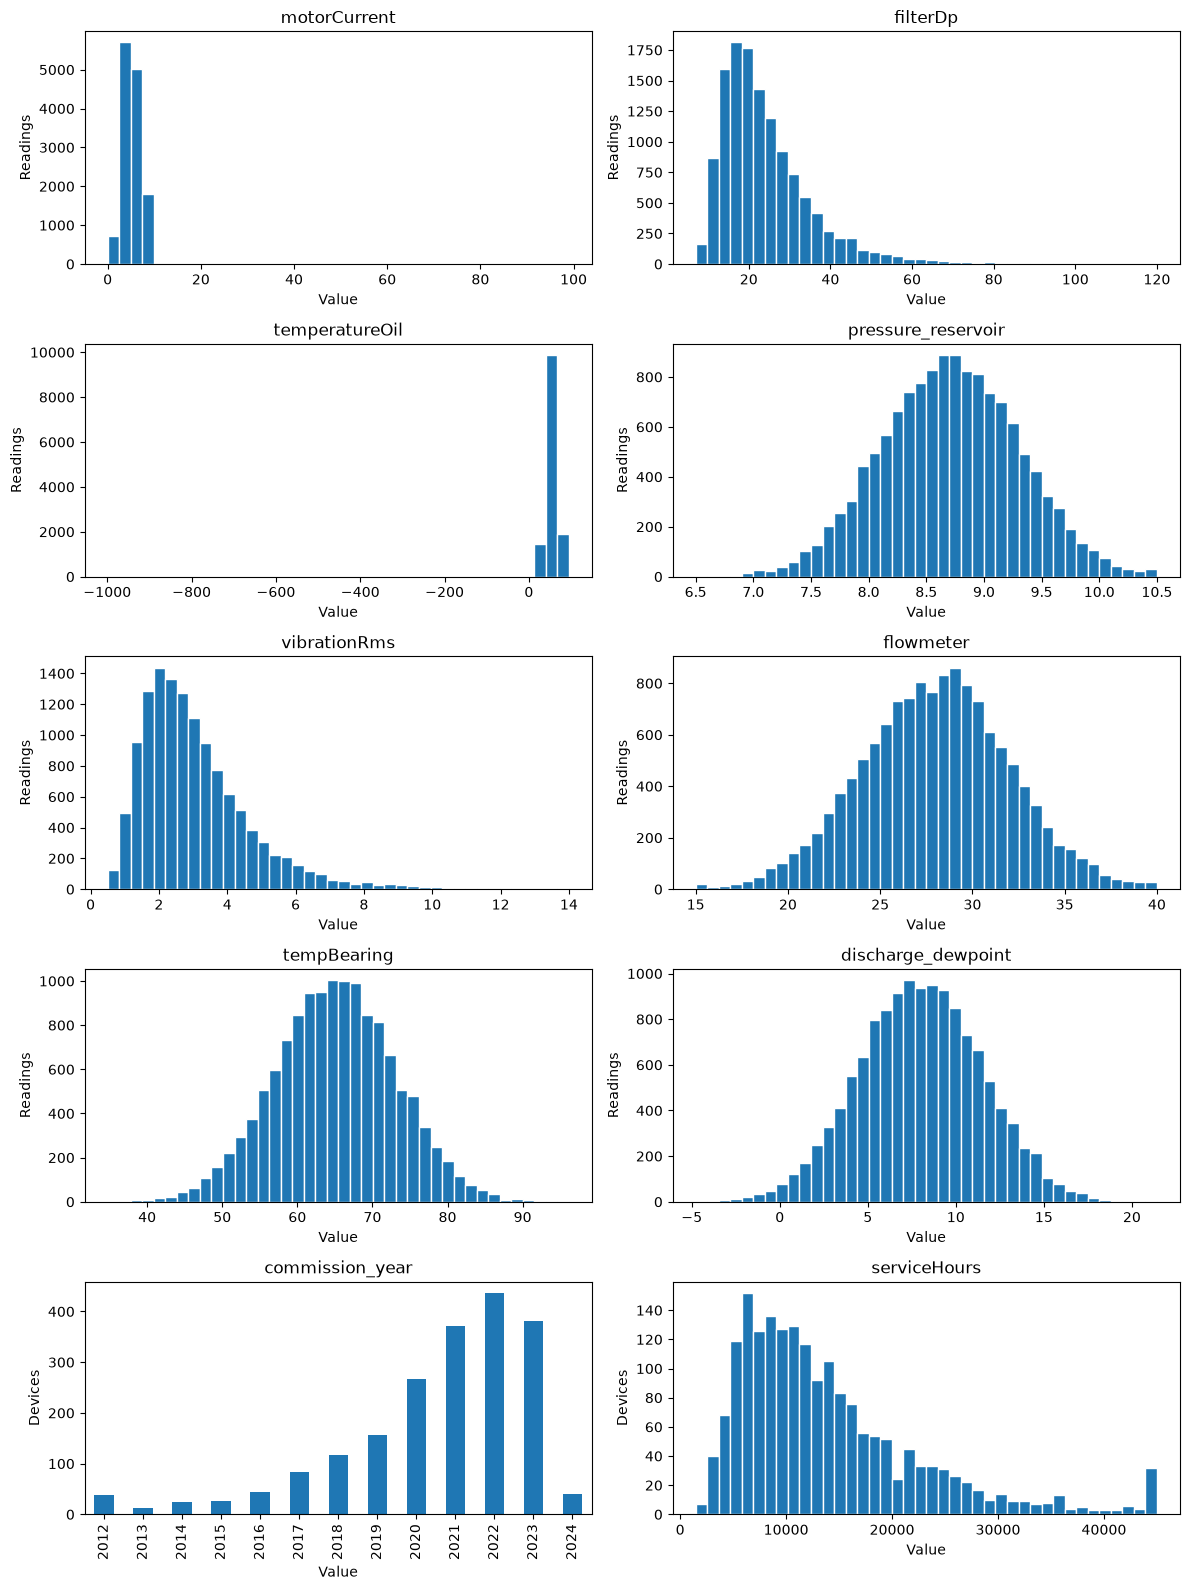

In [273]:
fig, axes = plt.subplots(5, 2, figsize=(12, 16))

for ax, (name, series) in zip(axes.flat, attributes.items()):
    values = series.dropna()
    values = values[np.isfinite(values)]

    if name == "commission_year":
        values.value_counts().sort_index().plot.bar(ax=ax)
        ax.set_ylabel("Devices")
    else:
        ax.hist(values, bins=40, edgecolor="white")
        ax.set_ylabel("Readings" if name in sensors else "Devices")

    ax.set_title(name)
    ax.set_xlabel("Value")

fig.tight_layout()
plt.show()

In [274]:
checks = pd.Series({
    "temperatureOil_equal_to_minus_999": readings_raw["temperatureOil"].eq(-999).sum(),
    "negative_serviceHours": units_raw["serviceHours"].lt(0).sum(),
    "unexpected_Failure_values": (
        readings_raw["Failure"].notna()
        & ~readings_raw["Failure"].isin([0, 1])
    ).sum(),
})

display(checks.to_frame("count"))

,count
temperatureOil_equal_to_minus_999,42
negative_serviceHours,0
unexpected_Failure_values,0


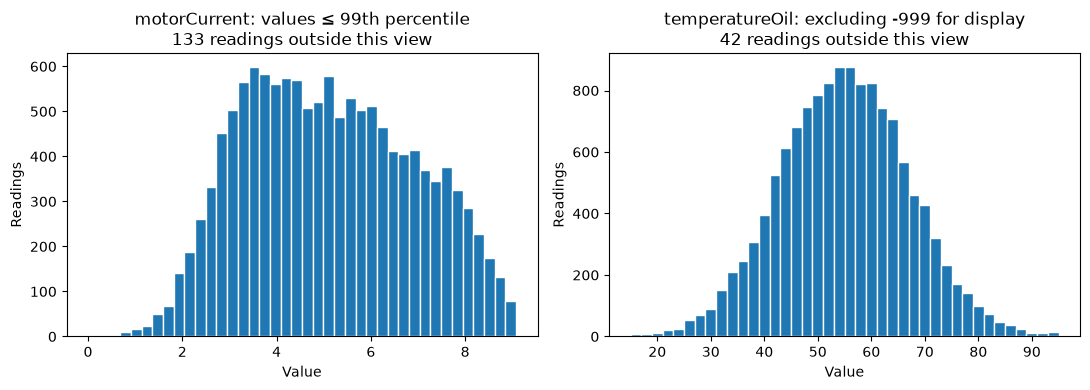

In [275]:
#create two plots for a closer view of the distributions
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

#show motorCurrent up to its 99th percentile
current = readings_raw["motorCurrent"].dropna()
upper = current.quantile(0.99)
central = current[current <= upper]

axes[0].hist(central, bins=40, edgecolor="white")
axes[0].set_title(
    f"motorCurrent: values ≤ 99th percentile\n"
    f"{len(current) - len(central)} readings outside this view"
)

#exclude the suspected invalid temperature code
oil = readings_raw["temperatureOil"].dropna()
visible_oil = oil[oil != -999]

axes[1].hist(visible_oil, bins=40, edgecolor="white")
axes[1].set_title(
    f"temperatureOil: excluding -999 for display\n"
    f"{oil.eq(-999).sum()} readings outside this view"
)

for ax in axes:
    ax.set_xlabel("Value")
    ax.set_ylabel("Readings")

fig.tight_layout()
plt.show()

#### Findings

- filterDp, vibrationRms and serviceHours have right-skewed distributions.
- pressure_reservoir, flowmeter, tempBearing and discharge_dewpoint
  appear approximately symmetric; normality has not been tested.
- motorCurrent has a median of 5.04 and a maximum of 99.
- temperatureOil contains 42 values of -999, affecting its mean,
  standard deviation and histogram scale.
- commission_year ranges from 2012 to 2024, with the highest frequency
  in 2022.
- Missing values: filterDp 539, vibrationRms 522, serviceHours 100.
- No infinite values, negative serviceHours or unexpected Failure
  values were found.

Observed ranges do not establish valid operating limits.
Suspicious values require investigation in section 1.2.

### 1.1(C) - Relationships Between Attributes

We examine sensor associations using Spearman correlation.
For this calculation, temperatureOil = -999 is treated as missing.
Each correlation uses rows where both measurements are available.

,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint
motorCurrent,1.00,0.01,0.01,-0.01,-0.01,0.01,-0.01,0.00
filterDp,0.01,1.00,0.01,-0.02,-0.00,-0.01,-0.01,-0.00
temperatureOil,0.01,0.01,1.00,0.01,-0.00,-0.00,0.00,0.01
pressure_reservoir,-0.01,-0.02,0.01,1.00,0.01,-0.00,-0.01,-0.01
vibrationRms,-0.01,-0.00,-0.00,0.01,1.00,-0.01,0.00,-0.00
flowmeter,0.01,-0.01,-0.00,-0.00,-0.01,1.00,-0.01,-0.00
tempBearing,-0.01,-0.01,0.00,-0.01,0.00,-0.01,1.00,0.00
discharge_dewpoint,0.00,-0.00,0.01,-0.01,-0.00,-0.00,0.00,1.00


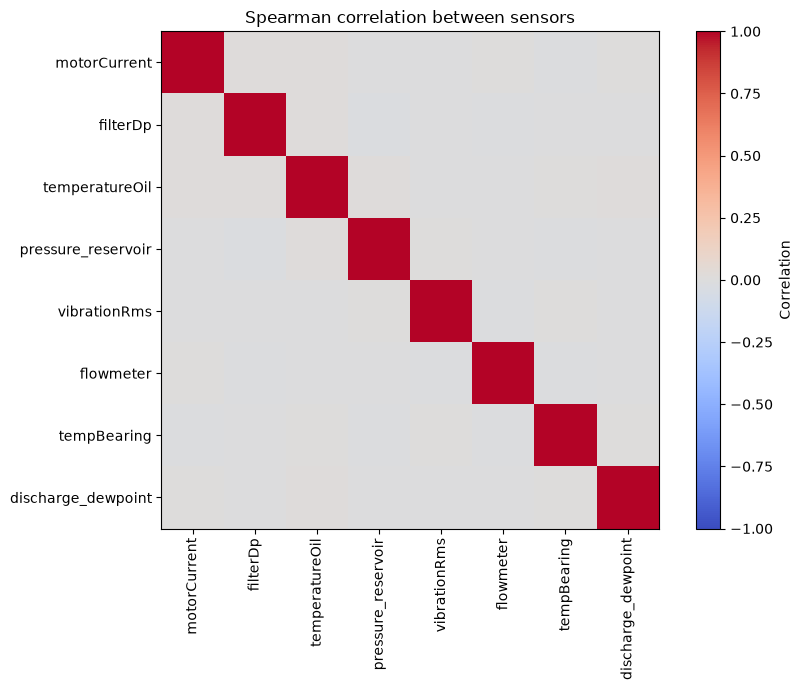

In [276]:
#create an analysis copy of the eight sensor columns
eda_sensor_data = readings_raw[sensors].copy()

#treat -999 as missing for correlation analysis
eda_sensor_data["temperatureOil"] = eda_sensor_data["temperatureOil"].mask(
    eda_sensor_data["temperatureOil"].eq(-999)
)

#calculate rank correlations using available pairs of measurements
correlation = eda_sensor_data.corr(method="spearman")
display(correlation.round(2))

#use a fixed colour scale from -1 to 1
fig, ax = plt.subplots(figsize=(9, 7))
plot = ax.imshow(correlation, vmin=-1, vmax=1, cmap="coolwarm")

#label sensors and add the colour scale
ax.set_xticks(range(len(sensors)), labels=sensors, rotation=90)
ax.set_yticks(range(len(sensors)), labels=sensors)
ax.set_title("Spearman correlation between sensors")
fig.colorbar(plot, ax=ax, label="Correlation")

#adjust spacing and display the heatmap
fig.tight_layout()
plt.show()

#### Pairwise Plots

We compare oil and bearing temperatures, reservoir pressure and flow,
and filter pressure difference and flow.

These pairs are selected for their related measurement roles.
Plots help inspect patterns that Spearman correlation may miss.

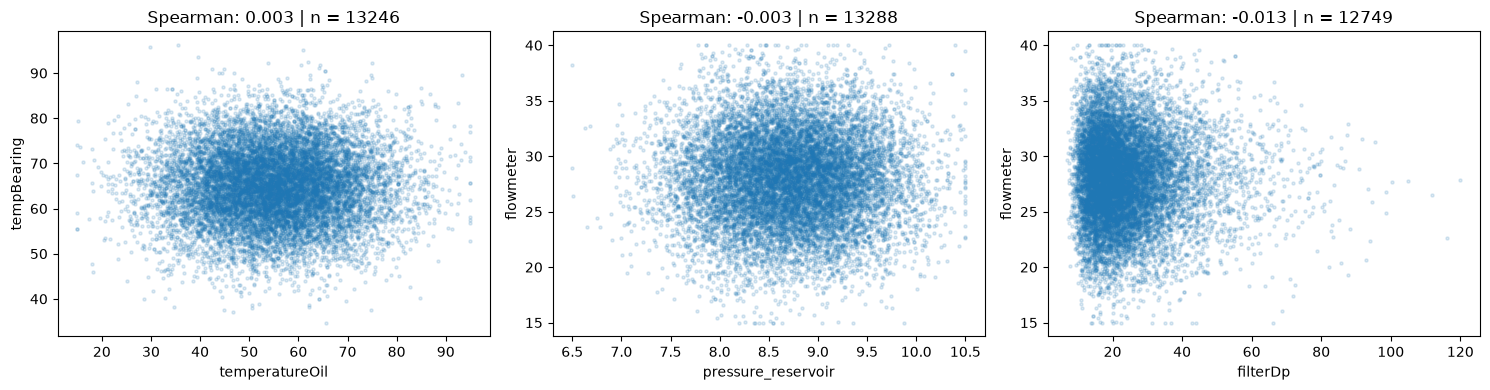

In [277]:
#inspect three sensor pairs for patterns beyond rank correlation
pairs = [
    ("temperatureOil", "tempBearing"),
    ("pressure_reservoir", "flowmeter"),
    ("filterDp", "flowmeter"),
]

fig, axes = plt.subplots(1, 3, figsize=(15, 4))

for ax, (x, y) in zip(axes, pairs):
    #use only rows where both measurements are available
    pair = eda_sensor_data[[x, y]].dropna()

    ax.scatter(pair[x], pair[y], s=5, alpha=0.15)
    ax.set_xlabel(x)
    ax.set_ylabel(y)
    ax.set_title(
        f"Spearman: {correlation.loc[x, y]:.3f} | n = {len(pair)}"
    )

fig.tight_layout()
plt.show()

#### Findings

Pairwise Spearman correlations are close to zero.
No strong monotonic associations were found among the eight sensors.
This does not establish independence or exclude nonlinear relationships.

### 1.1(D) - Relationships with Failure

We compare class frequencies and distributions of all ten selected attributes by Failure.
Sensor comparisons use readings; unit metadata comparisons use a temporary
many-to-one LEFT JOIN and are weighted by the number of readings per unit.
Oil temperature -999 is excluded using the analysis copy from section C.

In [278]:
#show the class balance
counts = readings_raw["Failure"].value_counts().sort_index()

display(pd.DataFrame({
    "rows": counts,
    "percent": (100 * counts / len(readings_raw)).round(2),
}))

#compare sensor medians and available observations
grouped = eda_sensor_data.groupby(readings_raw["Failure"])

print("Sensor medians:")
display(grouped.median().T.round(2))

print("Available observations:")
display(grouped.count().T)

,rows,percent
Failure,,
0,11663,87.77
1,1625,12.23


Sensor medians:


Failure,0,1
motorCurrent,5.11,4.57
filterDp,21.09,24.48
temperatureOil,54.89,55.39
pressure_reservoir,8.73,8.58
vibrationRms,2.70,2.88
flowmeter,28.11,27.80
tempBearing,64.77,67.32
discharge_dewpoint,7.88,8.67


Available observations:


Failure,0,1
motorCurrent,11663,1625
filterDp,11424,1325
temperatureOil,11629,1617
pressure_reservoir,11663,1625
vibrationRms,11443,1323
flowmeter,11663,1625
tempBearing,11663,1625
discharge_dewpoint,11663,1625


#### Sensor Distributions by Failure

Boxplots compare medians and spread between classes.
Outlier markers are hidden; observations are retained.

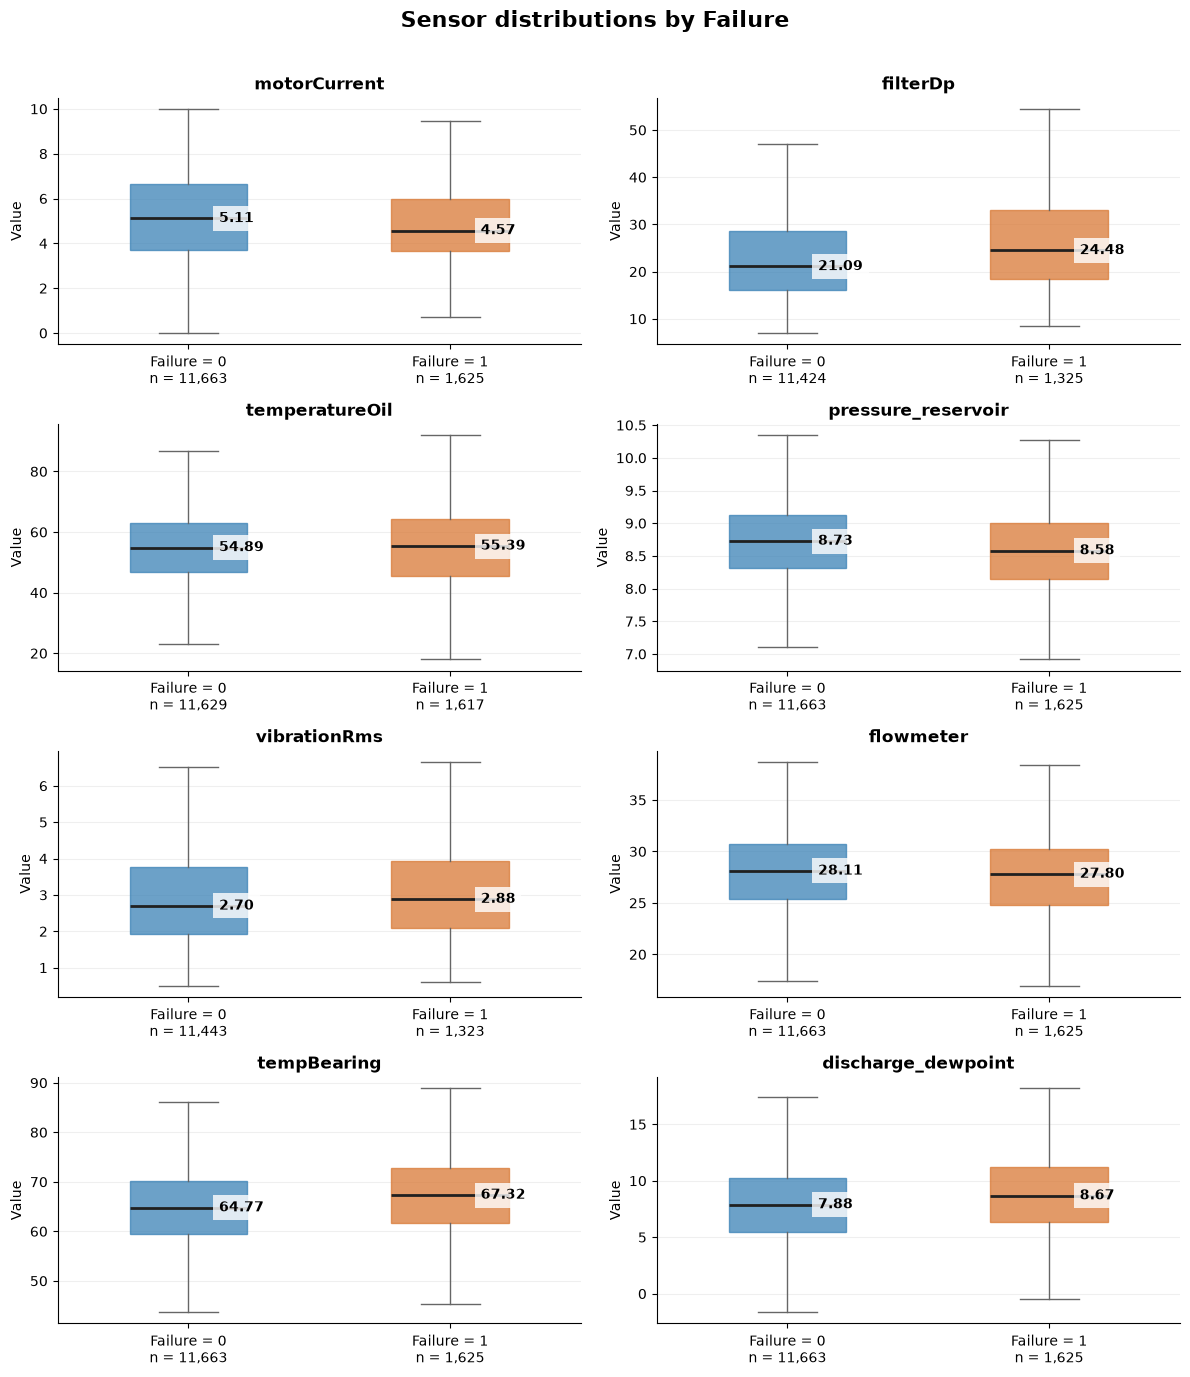

In [279]:
#compare sensor distributions between Failure classes
colors = ["#3B82B6", "#D97936"]
fig, axes = plt.subplots(4, 2, figsize=(12, 14))

for ax, column in zip(axes.flat, sensors):
    #select available measurements for each class
    groups = [
        eda_sensor_data.loc[readings_raw["Failure"].eq(label), column].dropna()
        for label in (0, 1)
    ]

    boxes = ax.boxplot(
        groups,
        widths=0.45,
        patch_artist=True,
        showfliers=False,
        whis=1.5,
        medianprops={"color": "#202020", "linewidth": 2},
        whiskerprops={"color": "#666666"},
        capprops={"color": "#666666"},
    )

    #colour each class and label its median
    for position, (box, values, color) in enumerate(
        zip(boxes["boxes"], groups, colors), start=1
    ):
        box.set(facecolor=color, edgecolor=color, alpha=0.75)

        ax.annotate(
            f"{values.median():.2f}",
            xy=(position, values.median()),
            xytext=(22, 0),
            textcoords="offset points",
            va="center",
            fontsize=10,
            fontweight="bold",
            bbox={"facecolor": "white", "edgecolor": "none", "alpha": 0.8},
        )

    #label classes and their available sample sizes
    ax.set_xticks(
        [1, 2],
        labels=[
            f"Failure = {label}\nn = {len(values):,}"
            for label, values in enumerate(groups)
        ],
    )
    ax.set_title(column, fontweight="bold")
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)

fig.suptitle("Sensor distributions by Failure", fontsize=16, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

In [280]:
# Missing measurement percentages by Failure class
display(
    eda_sensor_data.isna()
    .groupby(readings_raw["Failure"])
    .mean()
    .mul(100)
    .T
    .round(2)
)

Failure,0,1
motorCurrent,0.00,0.00
filterDp,2.05,18.46
temperatureOil,0.29,0.49
pressure_reservoir,0.00,0.00
vibrationRms,1.89,18.58
flowmeter,0.00,0.00
tempBearing,0.00,0.00
discharge_dewpoint,0.00,0.00


#### Unit Metadata by Failure

Reuse the normalized keys verified in section A: reading IDs follow `U[0-9]+`
(e.g. `U00596` maps to unit 596), while units use numeric IDs.
The temporary LEFT JOIN retains every reading, including unmatched records.
Missing metadata are included in missingness percentages but cannot enter
numeric summaries or boxplots. Counts below show available observations;
outlier markers are hidden without removing observations.

In [281]:
# Reuse section A keys without changing either original DataFrame
unit_attributes = ["commission_year", "serviceHours"]
assert unit_keys.notna().all() and unit_keys.is_unique
unit_lookup = units_raw[unit_attributes].copy()
unit_lookup.insert(0, "_unit_key", unit_keys)
metadata_by_failure = (
    readings_raw[["Failure"]]
    .assign(_unit_key=reading_keys, _reading_row=np.arange(len(readings_raw)))
    .merge(
        unit_lookup, on="_unit_key", how="left",
        validate="many_to_one", indicator=True, sort=False,
    )
)

# Confirm that no observations were added, removed or reordered
assert len(metadata_by_failure) == len(readings_raw)
assert metadata_by_failure["_reading_row"].is_unique
assert np.array_equal(metadata_by_failure["_reading_row"], np.arange(len(readings_raw)))
assert metadata_by_failure["_unit_key"].equals(reading_keys.reset_index(drop=True))
# Independently verify the joined values against a lookup by normalized unit ID
for column in unit_attributes:
    expected = reading_keys.map(unit_lookup.set_index("_unit_key")[column])
    pd.testing.assert_series_equal(
        metadata_by_failure[column], expected.reset_index(drop=True), check_names=False,
    )

print(f"LEFT JOIN: {len(readings_raw):,} readings -> {len(metadata_by_failure):,} rows")
print("Join coverage by Failure (including missing labels, if present):")
display(
    metadata_by_failure.groupby("Failure", dropna=False, observed=True).agg(
        rows=("_reading_row", "size"),
        unmatched_readings=("_merge", lambda values: values.eq("left_only").sum()),
    )
)
metadata_grouped = metadata_by_failure.groupby("Failure", dropna=False)[unit_attributes]
print("Available-value statistics (reading-weighted):")
display(metadata_grouped.agg(["count", "mean", "median", "std"]).round(2))
print("Missing metadata percentages, including unmatched readings:")
display(
    metadata_by_failure[unit_attributes].isna()
    .groupby(metadata_by_failure["Failure"], dropna=False)
    .mean().mul(100).T.round(2)
)
print("Missing metadata among matched readings only (counts):")
display(
    metadata_by_failure.loc[metadata_by_failure["_merge"].eq("both"), unit_attributes]
    .isna().groupby(metadata_by_failure["Failure"], dropna=False).sum().T
)

LEFT JOIN: 13,288 readings -> 13,288 rows
Join coverage by Failure (including missing labels, if present):


,rows,unmatched_readings
Failure,,
0,11663,119
1,1625,14


Available-value statistics (reading-weighted):


commission_year                        serviceHours            \
                  count     mean  median   std        count      mean   
Failure                                                                 
0                 11544  2020.66  2021.0  2.41        11001  13459.08   
1                  1611  2019.53  2020.0  2.94         1532  17514.58   

                            
          median       std  
Failure                     
0        11236.7   8416.31  
1        14750.8  10497.33

Missing metadata percentages, including unmatched readings:


Failure,0,1
commission_year,1.02,0.86
serviceHours,5.68,5.72


Missing metadata among matched readings only (counts):


Failure,0,1
commission_year,0,0
serviceHours,543,79


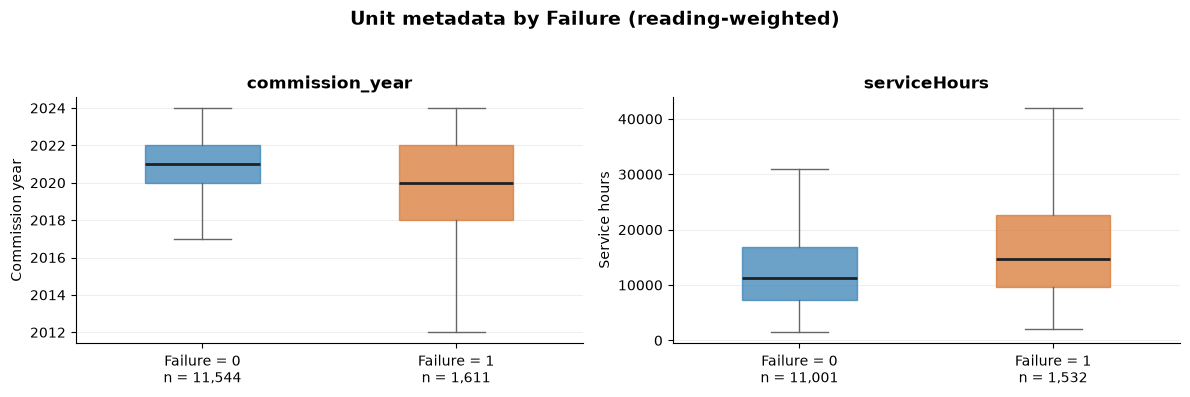

In [282]:
# Compare available unit metadata for the same two Failure classes
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for ax, column in zip(axes, unit_attributes):
    groups = [
        metadata_by_failure.loc[metadata_by_failure["Failure"].eq(label), column].dropna()
        for label in (0, 1)
    ]
    boxes = ax.boxplot(
        groups, widths=0.45, patch_artist=True, showfliers=False, whis=1.5,
        medianprops={"color": "#202020", "linewidth": 2},
        whiskerprops={"color": "#666666"}, capprops={"color": "#666666"},
    )
    for box, color in zip(boxes["boxes"], colors):
        box.set(facecolor=color, edgecolor=color, alpha=0.75)
    ax.set_xticks([1, 2], labels=[
        f"Failure = {label}\nn = {len(values):,}"
        for label, values in enumerate(groups)
    ])
    ax.set_title(column, fontweight="bold")
    ax.set_ylabel("Commission year" if column == "commission_year" else "Service hours")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)
    ax.spines[["top", "right"]].set_visible(False)
fig.suptitle("Unit metadata by Failure (reading-weighted)", fontsize=14, fontweight="bold")
fig.tight_layout(rect=(0, 0, 1, 0.94))
plt.show()

#### Findings

Failure = 1 accounts for 12.23% of readings.

Compared with Failure = 0, failure-labelled readings have higher medians
for filterDp (24.48 vs 21.09), tempBearing (67.32 vs 64.77) and
discharge_dewpoint (8.67 vs 7.88).
Motor current has a lower median (4.57 vs 5.11).

Missingness also differs: filterDp is missing in 18.46% of failure rows
versus 2.05% of non-failure rows; vibrationRms in 18.58% versus 1.89%.

Failure-labelled readings also come from units with earlier commission years:
the median is 2020 versus 2021, and the mean is 2019.53 versus 2020.66.
Their serviceHours median is higher (14,750.8 versus 11,236.7 hours), as is
the mean (17,514.58 versus 13,459.08 hours). The boxplots show overlapping
distributions, so these attributes do not separate the classes completely.

The join retains all 13,288 readings, with 119 unmatched non-failure readings
and 14 unmatched failure readings. commission_year is missing in 1.02% of
Failure = 0 and 0.86% of Failure = 1 rows; these are the unmatched readings.
serviceHours is missing in 5.68% and 5.72%, respectively, including both
unmatched records and missing values in matched units.

Metadata comparisons count readings, not distinct units: repeated readings
from the same unit receive repeated metadata values. These results do not
establish a unit-level relationship or account for repeated measurements.

These are descriptive associations, not evidence of causation or
advance failure prediction.

### 1.1(E) - Initial Project Decisions

- Sensor correlations show no strong monotonic associations.
  Nonlinear relationships remain possible.
- Investigate filterDp, tempBearing, discharge_dewpoint and motorCurrent
  as candidate predictors based on class differences.
- Investigate missingness indicators and whether missing measurements
  occur before or after failure.
- The temporary join suggests earlier commission years and higher serviceHours
  among failure-labelled readings. Investigate both as candidate predictors,
  accounting for repeated readings per unit and overlapping distributions.
  Retain and flag unmatched records in later preparation.
- Check the timing of metadata before using it as a predictor.
- Address duplicates, invalid values and inconsistent formats in 1.2.
- Account for class imbalance and repeated measurements when evaluating
  future models.

## 1.2 - Data Quality, Integration and Cleaning

### 1.2(A) - Data Issues and Initial Cleaning

Work on copies of the raw tables from Section 1.1. We remove exact duplicate
readings, standardize identifiers and dates, flag missing/invalid data and
integrate metadata without losing unmatched readings. Raw tables stay intact.


In [283]:
readings_clean = readings_raw.copy()
units_clean = units_raw.copy()
gateways_clean = gateways_raw.copy()


#### Checking Exact Duplicates
Exact duplicates have identical values in every column.
Matching device identifiers and dates alone do not prove that records
are duplicates. We inspect repeated records before removing them.

In [284]:
for name, df in [
    ("readings", readings_clean),
    ("units", units_clean),
    ("gateways", gateways_clean),
]:
    print(f"{name}: {df.duplicated().sum()} extra duplicate rows")

display(
    readings_clean.loc[readings_clean.duplicated(keep=False)]
    .sort_values(["unitId", "ts_cycle"])
    .head(20)
)

readings: 196 extra duplicate rows
units: 0 extra duplicate rows
gateways: 0 extra duplicate rows


,unitId,ts_cycle,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,Failure
12504,U00001,2023/02/27,6.47386,14.19043,44.05953,8.01864,5.32535,24.97808,72.22405,9.09212,0
13138,U00001,2023/02/27,6.47386,14.19043,44.05953,8.01864,5.32535,24.97808,72.22405,9.09212,0
8837,U00013,2023-10-06,5.13802,13.60035,36.16077,9.32805,2.59613,29.41965,65.08389,5.12061,0
13280,U00013,2023-10-06,5.13802,13.60035,36.16077,9.32805,2.59613,29.41965,65.08389,5.12061,0
3095,U00019,01 Sep 2023,6.60985,14.87267,64.95792,8.65423,2.52225,29.62823,72.63180,15.77390,1
13105,U00019,01 Sep 2023,6.60985,14.87267,64.95792,8.65423,2.52225,29.62823,72.63180,15.77390,1
9438,U00029,2023/12/20,6.90859,26.38209,46.74425,7.80743,5.20277,27.89719,64.32724,5.40653,1
13124,U00029,2023/12/20,6.90859,26.38209,46.74425,7.80743,5.20277,27.89719,64.32724,5.40653,1
135,U00037,03 Dec 2023,7.52436,18.43928,55.47770,8.62802,1.99813,29.25452,67.60258,9.92346,0
13180,U00037,03 Dec 2023,7.52436,18.43928,55.47770,8.62802,1.99813,29.25452,67.60258,9.92346,0


#### Removing Exact Duplicates

We treat rows identical in all columns as repeated records.
We keep the first occurrence and compare class counts before and after removal.

In [285]:
#remove exact copies while preserving the original table
readings_clean = readings_raw.drop_duplicates().copy()

#check the effect on target classes
comparison = pd.DataFrame({
    "before": readings_raw["Failure"].value_counts(),
    "after": readings_clean["Failure"].value_counts(),
}).sort_index()

comparison["removed"] = comparison["before"] - comparison["after"]
display(comparison)

print(f"Removed rows: {len(readings_raw) - len(readings_clean)}")
print(f"Remaining rows: {len(readings_clean)}")
print(f"Remaining exact duplicates: {readings_clean.duplicated().sum()}")

,before,after,removed
Failure,,,
0,11663,11498,165
1,1625,1594,31


Removed rows: 196
Remaining rows: 13092
Remaining exact duplicates: 0


#### Standardizing Device Keys

We use the numeric part of U-prefixed identifiers as a common device key.
This mapping is an assumption based on identifier structure.
Original identifiers are preserved; unmatched records are flagged.

In [286]:
#validate identifiers before conversion
ids = readings_clean["unitId"].astype("string").str.strip()
invalid = ~ids.str.fullmatch(r"U[0-9]+", na=False)

if invalid.any():
    display(readings_clean.loc[invalid, ["unitId"]])
    raise ValueError("Missing or unexpected identifiers in readings.")

#create common keys without replacing original identifiers
readings_clean["unit_key"] = pd.to_numeric(ids.str[1:]).astype("Int64")

for df in (units_clean, gateways_clean):
    df["unit_key"] = pd.to_numeric(
        df["unitId"], errors="raise"
    ).astype("Int64")

#check that normalization does not collapse distinct identifiers
key_mapping = readings_clean[["unitId", "unit_key"]].drop_duplicates()
assert key_mapping["unit_key"].is_unique, (
    "Different original identifiers map to the same key."
)

#require a unique device lookup before any join
assert units_clean["unit_key"].notna().all(), "Missing device keys in units."
assert units_clean["unit_key"].is_unique, "Duplicate device keys in units."

#flag unmatched readings instead of deleting them
readings_clean["unit_metadata_missing"] = ~readings_clean["unit_key"].isin(
    units_clean["unit_key"]
)

#inspect gateway links separately from missing identifiers
linked_gateways = gateways_clean.loc[gateways_clean["unit_key"].notna()]

display(pd.Series({
    "unmatched_readings": readings_clean["unit_metadata_missing"].sum(),
    "gateways_without_device_key": gateways_clean["unit_key"].isna().sum(),
    "extra_gateway_links_per_device": (
        linked_gateways["unit_key"].duplicated().sum()
    ),
    "unmatched_gateway_links": (
        ~linked_gateways["unit_key"].isin(units_clean["unit_key"])
    ).sum(),
}).to_frame("count"))

#check whether missing device metadata affects one class more often
display(
    readings_clean.groupby("Failure")["unit_metadata_missing"]
    .agg(rows="size", unmatched="sum", unmatched_rate="mean")
    .assign(unmatched_percent=lambda df: df["unmatched_rate"] * 100)
    .drop(columns="unmatched_rate")
    .round(2)
)

,count
unmatched_readings,131
gateways_without_device_key,14000
extra_gateway_links_per_device,0
unmatched_gateway_links,0


,rows,unmatched,unmatched_percent
Failure,,,
0,11498,117,1.02
1,1594,14,0.88


#### Standardizing Dates

Original date columns are preserved.
We parse explicit formats and flag ambiguous numeric dates.
Date-only records are distinguished from records containing a time.

In [287]:
def standardize_dates(series):
    text = series.astype("string").str.strip()
    parsed = pd.Series(pd.NaT, index=series.index, dtype="datetime64[ns]")

    #parse year-first dates and dates with named months
    for fmt in ("%Y-%m-%d", "%Y/%m/%d", "%d %b %Y"):
        candidate = pd.to_datetime(text, format=fmt, errors="coerce")
        parsed = parsed.fillna(candidate)

    #compare both interpretations of numeric dates
    month_first = pd.to_datetime(
        text, format="%m/%d/%Y, %H:%M:%S", errors="coerce"
    )
    day_first = pd.to_datetime(
        text, format="%d/%m/%Y, %H:%M:%S", errors="coerce"
    )

    ambiguous = (
        month_first.notna()
        & day_first.notna()
        & month_first.ne(day_first)
    )

    numeric = month_first.fillna(day_first).mask(ambiguous)
    parsed = parsed.fillna(numeric)

    #distinguish unresolved dates from original missing values
    status = pd.Series("unparsed", index=series.index, dtype="string")
    status.loc[text.isna() | text.eq("")] = "missing"
    status.loc[parsed.notna()] = "parsed"
    status.loc[ambiguous] = "ambiguous"

    return pd.DataFrame({
        "parsed": parsed,
        "status": status,
        "has_time": text.str.contains(
            r"\d{2}:\d{2}:\d{2}", regex=True, na=False
        ),
    })


for name, df, column in [
    ("readings", readings_clean, "ts_cycle"),
    ("gateways", gateways_clean, "seenLast"),
]:
    result = standardize_dates(df[column])

    #preserve source values and add parsed values and quality flags
    for suffix in result.columns:
        df[f"{column}_{suffix}"] = result[suffix]

    print(f"\n{name}: {column}")
    display(result["status"].value_counts().to_frame("rows"))

    #show examples requiring review
    unresolved = result["status"].isin(["ambiguous", "unparsed"])
    display(
        df.loc[unresolved, [column, f"{column}_status"]].head(5)
    )


readings: ts_cycle


,rows
status,
parsed,11958
ambiguous,1134


,ts_cycle,ts_cycle_status
4,"05/06/2023, 02:23:00",ambiguous
16,"06/02/2023, 17:32:00",ambiguous
22,"12/03/2023, 10:28:00",ambiguous
30,"04/07/2023, 18:40:00",ambiguous
32,"12/07/2023, 01:07:00",ambiguous



gateways: seenLast


,rows
status,
parsed,14605
ambiguous,1395


,seenLast,seenLast_status
2,"08/10/2024, 00:00:00",ambiguous
4,"06/01/2024, 00:00:00",ambiguous
7,"04/09/2024, 00:00:00",ambiguous
14,"09/06/2024, 00:00:00",ambiguous
19,"05/08/2024, 00:00:00",ambiguous


#### Cleaning Category Whitespace

We remove surrounding whitespace from class_duty.
Original values are preserved. Category codes are not merged without
a confirmed mapping.

In [288]:
#remove surrounding spaces while preserving original categories
original = units_clean["class_duty"].astype("string")
units_clean["class_duty_clean"] = original.str.strip()

changed = original.ne(units_clean["class_duty_clean"]).fillna(False)

print(f"Rows changed: {changed.sum()}")
print(f"Unique categories before: {original.nunique()}")
print(f"Unique categories after: {units_clean['class_duty_clean'].nunique()}")

#make spaces visible in the comparison
display(
    pd.DataFrame({
        "original": original.map(repr),
        "cleaned": units_clean["class_duty_clean"].map(repr),
    })
    .value_counts()
    .rename("rows")
    .reset_index()
)

Rows changed: 202
Unique categories before: 20
Unique categories after: 10


,original,cleaned,rows
0,'1','1',277
1,'L','L',239
2,'light','light',226
3,'med','med',189
4,'H','H',165
5,'N','N',153
6,'3','3',141
7,'2','2',138
8,'heavy','heavy',136
9,'normal','normal',134


#### Missing Values

We inspect missing values in source columns and compare sensor
missingness between Failure classes. Missing measurements are retained;
imputation will be fitted on training data in Phase 2.

In [289]:
#report missing values in source columns only
reports = []

for name, df, source in [
    ("readings", readings_clean, readings_raw),
    ("units", units_clean, units_raw),
    ("gateways", gateways_clean, gateways_raw),
]:
    missing = df[source.columns].isna()

    reports.append(pd.DataFrame({
        "table": name,
        "column": source.columns,
        "missing_count": missing.sum().to_numpy(),
        "missing_percent": (missing.mean() * 100).to_numpy(),
    }))

missing_summary = pd.concat(reports, ignore_index=True)

display(
    missing_summary.loc[missing_summary["missing_count"] > 0]
    .round(2)
    .reset_index(drop=True)
)

#compare sensor missingness between classes
display(
    readings_clean[sensors].isna()
    .groupby(readings_clean["Failure"])
    .mean()
    .mul(100)
    .T
    .round(2)
)

#preserve missingness information as explicit flags
for column in ["filterDp", "vibrationRms"]:
    readings_clean[f"{column}_missing"] = readings_clean[column].isna()

units_clean["serviceHours_missing"] = units_clean["serviceHours"].isna()

,table,column,missing_count,missing_percent
0,readings,filterDp,531,4.06
1,readings,vibrationRms,511,3.90
2,units,serviceHours,100,5.00
3,gateways,unitId,14000,87.50


Failure,0,1
motorCurrent,0.00,0.00
filterDp,2.05,18.51
temperatureOil,0.00,0.00
pressure_reservoir,0.00,0.00
vibrationRms,1.86,18.63
flowmeter,0.00,0.00
tempBearing,0.00,0.00
discharge_dewpoint,0.00,0.00


#### Handling Invalid Oil Temperature

We treat temperatureOil = -999 as an invalid measurement.
Its exact meaning is undocumented. Original values are preserved;
a cleaned column replaces -999 with missing values.

In [290]:
#check the suspected invalid value against the remaining measurements
invalid = readings_clean["temperatureOil"].eq(-999)
other_values = readings_clean.loc[~invalid, "temperatureOil"]

print(f"Values equal to -999: {invalid.sum()}")
print(f"Other values: {other_values.min()} to {other_values.max()}")

#preserve the original column and flag invalid measurements
readings_clean["temperatureOil_invalid"] = invalid
readings_clean["temperatureOil_clean"] = readings_clean["temperatureOil"].mask(invalid)

print(
    "Missing cleaned temperatures:",
    readings_clean["temperatureOil_clean"].isna().sum(),
)

#check how often invalid temperatures occur in each class
display(
    readings_clean.groupby("Failure")["temperatureOil_invalid"]
    .agg(count="sum", percent=lambda values: values.mean() * 100)
    .round(2)
)

Values equal to -999: 41
Other values: 15.0 to 95.0
Missing cleaned temperatures: 41


,count,percent
Failure,,
0,33,0.29
1,8,0.50


#### Integrating Device Metadata

We join readings with units using unit_key.
A left join preserves unmatched readings.
The many-to-one constraint prevents duplicate device keys from
multiplying measurements.

Metadata availability at the measurement time remains to be verified
before predictive modelling.

In [291]:
#preserve source row identifiers for checking the join
assert readings_clean.index.is_unique, "Reading row identifiers are not unique."
assert units_clean["unit_key"].notna().all(), "Missing device keys."

source = readings_clean.assign(reading_row_id=readings_clean.index)

#avoid adding a second copy of the original unitId column
device_metadata = units_clean.drop(columns="unitId")

#attach device metadata while retaining all readings
integrated_clean = source.merge(
    device_metadata,
    on="unit_key",
    how="left",
    validate="many_to_one",
    indicator="device_match",
    sort=False,
)

#verify that observations and target labels were preserved
assert len(integrated_clean) == len(readings_clean), "The join changed the row count."
assert integrated_clean["reading_row_id"].is_unique, "The join duplicated readings."

pd.testing.assert_series_equal(
    integrated_clean.set_index("reading_row_id")["Failure"].sort_index(),
    source.set_index("reading_row_id")["Failure"].sort_index(),
)

#compare flag values using the same boolean type
pd.testing.assert_series_equal(
    integrated_clean["device_match"].eq("left_only").astype("boolean"),
    integrated_clean["unit_metadata_missing"].astype("boolean"),
    check_names=False,
)

print(f"Rows before: {len(readings_clean)}")
print(f"Rows after: {len(integrated_clean)}")
display(integrated_clean["device_match"].value_counts().to_frame("rows"))

display(
    integrated_clean[[
        "unitId", "unit_key", "Failure",
        "commission_year", "serviceHours", "device_match",
    ]].head()
)

Rows before: 13092
Rows after: 13092


,rows
device_match,
both,12961
left_only,131
right_only,0


,unitId,unit_key,Failure,commission_year,serviceHours,device_match
0,U00596,596,0,2021.0,11693.5,both
1,U00540,540,0,2019.0,18726.1,both
2,U00927,927,0,2020.0,14315.5,both
3,U01299,1299,0,2017.0,NaN,both
4,U01092,1092,0,2023.0,4149.4,both


The join preserved all 13,092 readings and their Failure labels.
Device metadata matched 12,961 readings; 131 remained unmatched.
No readings were duplicated by the join.

### 1.2(B) - Data Consistency Checks

We check target labels, non-finite measurements, negative service hours
and readings dated before the commissioning year.

Temporal checks use only resolved dates and available device metadata.
Flagged records are retained for review.

In [292]:
#use the cleaned temperature in numeric checks
sensor_columns = [
    "motorCurrent", "filterDp", "temperatureOil_clean",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]

#distinguish missing measurements from infinite values
values = integrated_clean[sensor_columns]

display(pd.DataFrame({
    "missing": values.isna().sum(),
    "infinite": (values.notna() & ~np.isfinite(values)).sum(),
}))

#flag invalid or missing target labels
integrated_clean["invalid_target"] = ~integrated_clean["Failure"].isin([0, 1])

#check service hours only where available
hours = integrated_clean["serviceHours"]
integrated_clean["negative_serviceHours"] = (
    hours.lt(0).where(hours.notna()).astype("boolean")
)

#check years only when the date and commissioning year are available
date = integrated_clean["ts_cycle_parsed"]
year = integrated_clean["commission_year"]
eligible = date.notna() & year.notna()

integrated_clean["before_commissioning"] = (
    date.dt.year.lt(year).where(eligible).astype("boolean")
)

#report checked, flagged and unavailable cases separately
flags = integrated_clean[[
    "invalid_target",
    "negative_serviceHours",
    "before_commissioning",
]]

display(pd.DataFrame({
    "checked": flags.notna().sum(),
    "flagged": flags.sum(),
    "not_checkable": flags.isna().sum(),
}))

#inspect examples of temporal inconsistencies
display(
    integrated_clean.loc[
        integrated_clean["before_commissioning"].fillna(False),
        ["unitId", "ts_cycle", "ts_cycle_parsed", "commission_year"],
    ].head(10)
)

,missing,infinite
motorCurrent,0,0
filterDp,531,0
temperatureOil_clean,41,0
pressure_reservoir,0,0
vibrationRms,511,0
flowmeter,0,0
tempBearing,0,0
discharge_dewpoint,0,0


,checked,flagged,not_checkable
invalid_target,13092,0,0
negative_serviceHours,12349,0,743
before_commissioning,11840,238,1252


,unitId,ts_cycle,ts_cycle_parsed,commission_year
9,U01913,2023-12-12,2023-12-12 00:00:00,2024.0
15,U00343,2023/07/29,2023-07-29 00:00:00,2024.0
43,U01354,2023/09/30,2023-09-30 00:00:00,2024.0
165,U01356,29 Jan 2023,2023-01-29 00:00:00,2024.0
259,U00343,2023/06/07,2023-06-07 00:00:00,2024.0
288,U00155,2023/01/13,2023-01-13 00:00:00,2024.0
305,U01516,"09/20/2023, 02:18:00",2023-09-20 02:18:00,2024.0
328,U00809,"10/16/2023, 04:17:00",2023-10-16 04:17:00,2024.0
395,U01381,2023/01/01,2023-01-01 00:00:00,2024.0
573,U00617,19 Sep 2023,2023-09-19 00:00:00,2024.0


#### Temporal Findings

238 readings precede the recorded commissioning year.
We retain and flag these records because the incorrect field is unknown.
For 1,252 readings, the temporal check is unavailable.

#### Device–Gateway Consistency

We compare depot identifiers for gateways linked to devices.
This checks agreement between the supplied metadata tables,
not historical gateway assignments.

In [293]:
#check only gateways with a device key
linked = gateways_clean.loc[gateways_clean["unit_key"].notna()]

#match gateway and device depots without multiplying records
depot_check = linked[["id_gateway", "unit_key", "id_depot"]].merge(
    units_clean[["unit_key", "id_depot"]],
    on="unit_key",
    how="left",
    validate="one_to_one",
    suffixes=("_gateway", "_unit"),
    indicator=True,
)

#compare only matched records with both depot values available
eligible = (
    depot_check["_merge"].eq("both")
    & depot_check["id_depot_gateway"].notna()
    & depot_check["id_depot_unit"].notna()
)

mismatch = eligible & depot_check["id_depot_gateway"].ne(
    depot_check["id_depot_unit"]
)

display(pd.Series({
    "checked_links": eligible.sum(),
    "depot_mismatches": mismatch.sum(),
    "not_checkable": (~eligible).sum(),
}).to_frame("count"))

display(depot_check.loc[mismatch].head(10))



,count
checked_links,2000
depot_mismatches,0
not_checkable,0


,id_gateway,unit_key,id_depot_gateway,id_depot_unit,_merge


#### Checking Conflicting Labels

We check whether identical device, timestamp and sensor records have
different Failure labels. Only resolved timestamps with explicit times
are checked. Conflicts are reported without automatic relabelling.

In [294]:
#use only resolved timestamps containing an explicit time
eligible = (
    integrated_clean["unit_key"].notna()
    & integrated_clean["ts_cycle_parsed"].notna()
    & integrated_clean["ts_cycle_has_time"]
)

#compare original measurements, including original oil temperature
original_sensors = [
    "motorCurrent", "filterDp", "temperatureOil",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]
keys = ["unit_key", "ts_cycle_parsed"] + original_sensors

#keep missing sensor values as part of the record comparison
label_counts = (
    integrated_clean.loc[eligible]
    .groupby(keys, dropna=False)["Failure"]
    .nunique()
)

conflicts = label_counts[label_counts > 1].reset_index(
    name="distinct_labels"
)

print(f"Checked readings: {eligible.sum()}")
print(f"Readings outside this check: {(~eligible).sum()}")
print(f"Conflicting record groups: {len(conflicts)}")

display(conflicts.head(10))

Checked readings: 2059
Readings outside this check: 11033
Conflicting record groups: 0


,unit_key,ts_cycle_parsed,motorCurrent,filterDp,temperatureOil,pressure_reservoir,vibrationRms,flowmeter,tempBearing,discharge_dewpoint,distinct_labels


No conflicting labels were found among 2,059 eligible readings.
The remaining 11,033 readings were outside this check.

### 1.2(C) - Outlier Treatment

We compare IQR-based row removal and clipping at the 5th and 95th
percentiles on separate copies. Missing values are preserved.
Statistical outliers are not automatically considered measurement errors.

Thresholds calculated here are exploratory. For modelling, they must
be fitted on training data only.

In [295]:
#use the cleaned temperature and exclude identifiers and target labels
outlier_columns = [
    "motorCurrent", "filterDp", "temperatureOil_clean",
    "pressure_reservoir", "vibrationRms", "flowmeter",
    "tempBearing", "discharge_dewpoint",
]
cleaning_baseline = integrated_clean.copy()
values = cleaning_baseline[outlier_columns]

#Method 1: flag values outside the 1.5 IQR boundaries
q1 = values.quantile(0.25)
q3 = values.quantile(0.75)
iqr = q3 - q1

lower_iqr = q1 - 1.5 * iqr
upper_iqr = q3 + 1.5 * iqr

outside_iqr = values.lt(lower_iqr) | values.gt(upper_iqr)
remove_row = outside_iqr.any(axis=1)

#remove rows containing at least one flagged sensor value
iqr_removed = cleaning_baseline.loc[~remove_row].copy()

#Method 2: clip values without removing rows
lower_clip = values.quantile(0.05)
upper_clip = values.quantile(0.95)

clipped = cleaning_baseline.copy()
clipped[outlier_columns] = values.clip(
    lower=lower_clip, upper=upper_clip, axis="columns"
)

#count actual changes; missing values do not count as changes
changed = values.notna() & values.ne(clipped[outlier_columns])

display(pd.DataFrame({
    "iqr_lower": lower_iqr,
    "iqr_upper": upper_iqr,
    "iqr_flagged_values": outside_iqr.sum(),
    "clip_lower": lower_clip,
    "clip_upper": upper_clip,
    "clipped_values": changed.sum(),
}).round(2))

,iqr_lower,iqr_upper,iqr_flagged_values,clip_lower,clip_upper,clipped_values
motorCurrent,-0.63,10.86,14,2.43,8.24,1310
filterDp,-2.60,47.91,513,11.65,45.90,1256
temperatureOil_clean,22.17,87.56,89,35.08,74.67,1306
pressure_reservoir,7.07,10.35,80,7.72,9.68,1310
vibrationRms,-0.86,6.57,472,1.18,6.14,1258
flowmeter,17.28,38.69,108,21.38,34.61,1310
tempBearing,43.34,86.69,86,51.71,78.25,1310
discharge_dewpoint,-1.61,17.58,75,2.24,13.78,1310


#### Impact on Failure Classes

We compare retained rows, failure proportions and removal rates
within each class.

In [296]:
#compare dataset sizes and class proportions
variants = {
    "baseline": cleaning_baseline,
    "iqr_removal": iqr_removed,
    "percentile_clipping": clipped,
}

display(pd.DataFrame([
    {
        "method": name,
        "rows": len(df),
        "removed_rows": len(cleaning_baseline) - len(df),
        "failure_rows": df["Failure"].eq(1).sum(),
        "failure_percent": df["Failure"].eq(1).mean() * 100,
    }
    for name, df in variants.items()
]).round(2))

#measure removal rates separately within each class
removal_impact = (
    cleaning_baseline.assign(removed_by_iqr=remove_row)
    .groupby("Failure")["removed_by_iqr"]
    .agg(total="size", removed="sum")
)
removal_impact["removed_percent"] = (
    100 * removal_impact["removed"] / removal_impact["total"]
)

display(removal_impact.round(2))

#verify that clipping preserved rows, labels and missing values
assert clipped.index.equals(cleaning_baseline.index)
pd.testing.assert_series_equal(clipped["Failure"], cleaning_baseline["Failure"])
assert clipped[outlier_columns].isna().equals(values.isna())

,method,rows,removed_rows,failure_rows,failure_percent
0,baseline,13092,0,1594,12.18
1,iqr_removal,11703,1389,1352,11.55
2,percentile_clipping,13092,0,1594,12.18


,total,removed,removed_percent
Failure,,,
0,11498,1147,9.98
1,1594,242,15.18


#### Distribution Comparison

We compare filterDp and vibrationRms before and after both treatments.
Outlier markers are hidden; each panel uses one scale for all methods.

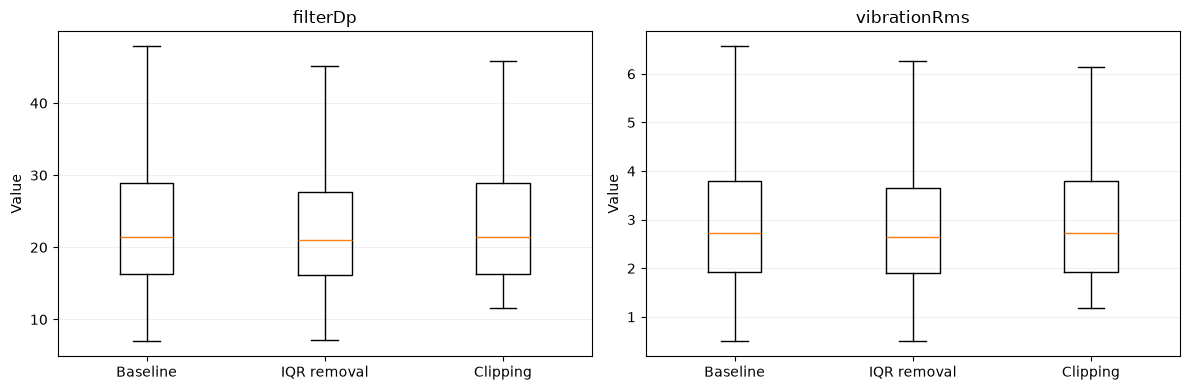

In [297]:
#compare the sensors with the most IQR-flagged values
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

for ax, column in zip(axes, ["filterDp", "vibrationRms"]):
    groups = [
        df[column].dropna()
        for df in (cleaning_baseline, iqr_removed, clipped)
    ]

    ax.boxplot(groups, showfliers=False)
    ax.set_xticks([1, 2, 3], labels=["Baseline", "IQR removal", "Clipping"])
    ax.set_title(column)
    ax.set_ylabel("Value")
    ax.grid(axis="y", alpha=0.2)
    ax.set_axisbelow(True)

fig.tight_layout()
plt.show()

#### Findings and Decision

IQR removal excluded 1,389 readings, including 242 failure-labelled rows.
It removed 15.18% of failure rows versus 9.98% of non-failure rows.
The failure proportion decreased from 12.18% to 11.55%.

Clipping preserved all rows and labels but modified approximately 10%
of available values per sensor, potentially suppressing failure signals.

We retain baseline as the working dataset and keep both treatments
as experimental alternatives. Neither method is selected as universally
better without model validation.

### 1.2 - Summary and Remaining Limitations

- Removed 196 exact duplicate rows.
- Standardized device keys and category whitespace.
- Replaced 41 invalid oil temperatures in a separate cleaned column.
- Integrated device metadata without changing the 13,092 reading rows.
- Compared two outlier treatments; retained baseline for further analysis.

Unresolved issues:
- 1,134 reading dates and 1,395 gateway dates remain ambiguous.
- 131 readings lack device metadata.
- 238 readings precede the recorded commissioning year.
- Missing measurements remain unfilled.
- Gateway metadata is not included in the working dataset.

## 1.3 - Statistical Hypothesis Testing

We test whether service hours and original filterDp missingness are associated
with Failure, then assess power. These questions come from the EDA, so the
results are exploratory.

### 1.3 - Dataset Preparation and Independent Units

Use the integrated baseline from Section 1.2, without repeating cleaning or
applying the experimental outlier treatments. Keep original labels and missing
values. Gateway metadata is not included.

In [298]:
hypothesis_data = cleaning_baseline.copy()
pd.testing.assert_frame_equal(hypothesis_data, integrated_clean)
assert len(hypothesis_data) == len(readings_clean)
assert hypothesis_data["reading_row_id"].is_unique
print(f"Retained integrated baseline for hypotheses: {len(hypothesis_data):,} readings")


Retained integrated baseline for hypotheses: 13,092 readings


#### Join and label validation

Reading IDs such as `U00596` map to numeric unit key 596 after format validation.
The many-to-one LEFT JOIN keeps unmatched readings and requires unique unit keys.
The checks below verify service hours against the lookup and preserve source
Failure labels and filterDp values.

In [299]:
assert units_clean["unit_key"].notna().all() and units_clean["unit_key"].is_unique
assert len(hypothesis_data) == len(readings_clean)
assert hypothesis_data["reading_row_id"].is_unique
assert set(hypothesis_data["reading_row_id"]) == set(readings_clean.index)
assert hypothesis_data["Failure"].isin([0, 1]).all(), "Review missing or invalid labels."
by_source = hypothesis_data.set_index("reading_row_id").sort_index()
for column in ["unitId", "unit_key", "Failure", "filterDp"]:
    pd.testing.assert_series_equal(by_source[column], readings_clean[column].sort_index().rename_axis("reading_row_id"))
expected_hours = hypothesis_data["unit_key"].map(units_clean.set_index("unit_key")["serviceHours"])
pd.testing.assert_series_equal(hypothesis_data["serviceHours"], expected_hours, check_names=False)
assert np.array_equal(
    hypothesis_data["device_match"].eq("left_only"),
    ~hypothesis_data["unit_key"].isin(units_clean["unit_key"]),
)
assert np.isfinite(hypothesis_data["serviceHours"].dropna()).all()
assert hypothesis_data["serviceHours"].dropna().ge(0).all()
assert np.isfinite(hypothesis_data["filterDp"].dropna()).all()

required_columns = ["Failure", "serviceHours", "filterDp", "unitId"]
display(pd.DataFrame({
    "missing_count": hypothesis_data[required_columns].isna().sum(),
    "missing_percent": hypothesis_data[required_columns].isna().mean().mul(100),
}).round(2))
display(hypothesis_data.groupby("Failure", dropna=False).agg(
    rows=("Failure", "size"), unique_units=("unit_key", "nunique"),
    unmatched_readings=("device_match", lambda x: x.eq("left_only").sum()),
    missing_serviceHours=("serviceHours", lambda x: x.isna().sum()),
    missing_filterDp=("filterDp", lambda x: x.isna().sum()),
).assign(percent=lambda x: 100 * x["rows"] / len(hypothesis_data)).round(2))
print("Unique units:", hypothesis_data["unit_key"].nunique())
print("Unmatched units:", hypothesis_data.loc[hypothesis_data["device_match"].eq("left_only"), "unit_key"].nunique())
print("Missing serviceHours among matched readings:",
      hypothesis_data.loc[hypothesis_data["device_match"].eq("both"), "serviceHours"].isna().sum())
print("Join, source-value and label checks passed.")

,missing_count,missing_percent
Failure,0,0.00
serviceHours,743,5.68
filterDp,531,4.06
unitId,0,0.00


,rows,unique_units,unmatched_readings,missing_serviceHours,missing_filterDp,percent
Failure,,,,,,
0,11498,2104,117,650,236,87.82
1,1594,1030,14,93,295,12.18


Unique units: 2117
Unmatched units: 119
Missing serviceHours among matched readings: 612
Join, source-value and label checks passed.


#### Repeated measurements and changing labels

We count readings and distinct Failure labels per unit. Units with both labels
appear in both row-level classes. We also check label changes between resolved,
nonconflicting timestamps. Ambiguous dates stay in the dataset but are excluded
from this time check. Date-only records cannot establish order within a day.

,readings_per_unit
count,2117.00
mean,6.18
std,2.75
min,1.00
25%,4.00
50%,6.00
75%,8.00
max,18.00


,units
label_pattern,
Only Failure = 0,1087
Both labels,1017
Only Failure = 1,13


,readings
ts_cycle_status,
parsed,11958
ambiguous,1134


,count
units_with_both_labels_all_readings,1017
units_with_both_labels_resolved_dates,956
unit_timestamp_groups_with_both_labels,13
units_with_ordered_label_changes,950
adjacent_changes_at_resolved_nonconflicting_times,1980
readings_with_explicit_time,3193


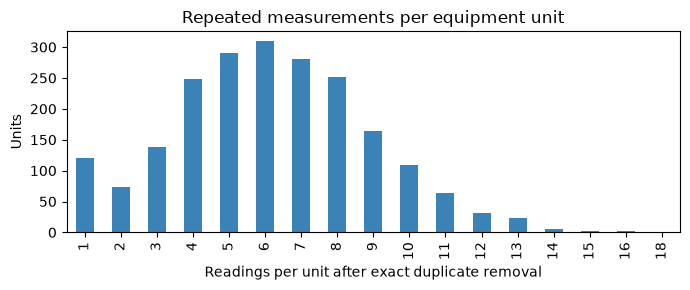

In [300]:
unit_summary = hypothesis_data.groupby("unit_key").agg(
    unitId=("unitId", "first"), readings=("Failure", "size"),
    failure_labels=("Failure", "nunique"), failure_min=("Failure", "min"),
    failure_max=("Failure", "max"),
)
unit_summary["label_pattern"] = np.select(
    [unit_summary["failure_labels"].eq(2), unit_summary["failure_max"].eq(0)],
    ["Both labels", "Only Failure = 0"], default="Only Failure = 1",
)
display(unit_summary["readings"].describe().to_frame("readings_per_unit").round(2))
display(unit_summary["label_pattern"].value_counts().to_frame("units"))
display(hypothesis_data["ts_cycle_status"].value_counts(dropna=False).to_frame("readings"))
resolved = hypothesis_data.loc[hypothesis_data["ts_cycle_parsed"].notna()]
at_time = resolved.groupby(["unit_key", "ts_cycle_parsed"]).agg(
    distinct_labels=("Failure", "nunique"), Failure=("Failure", "first"),
)
ordered = at_time.loc[at_time["distinct_labels"].eq(1)].reset_index().sort_values(
    ["unit_key", "ts_cycle_parsed"]
)
previous = ordered.groupby("unit_key")["Failure"].shift()
changed = previous.notna() & ordered["Failure"].ne(previous)
display(pd.Series({
    "units_with_both_labels_all_readings": unit_summary["failure_labels"].eq(2).sum(),
    "units_with_both_labels_resolved_dates": resolved.groupby("unit_key")["Failure"].nunique().eq(2).sum(),
    "unit_timestamp_groups_with_both_labels": at_time["distinct_labels"].eq(2).sum(),
    "units_with_ordered_label_changes": ordered.loc[changed, "unit_key"].nunique(),
    "adjacent_changes_at_resolved_nonconflicting_times": changed.sum(),
    "readings_with_explicit_time": hypothesis_data["ts_cycle_has_time"].sum(),
}).to_frame("count"))

fig, ax = plt.subplots(figsize=(7, 3))
unit_summary["readings"].value_counts().sort_index().plot.bar(ax=ax, color="#3B82B6")
ax.set_xlabel("Readings per unit after exact duplicate removal")
ax.set_ylabel("Units")
ax.set_title("Repeated measurements per equipment unit")
fig.tight_layout()
plt.show()

#### Independent unit of analysis

Select **one random reading per unit**, using fixed seed **133** and stable
sorting. Sample before excluding missing service hours, preserve the selected
Failure label, and use the same rows for both tests. Missing filterDp remains
an outcome. We do not classify units by whether they ever failed, which would
favour units observed more often.

This gives each unit equal weight and describes a random recorded occasion,
not future failure risk. Different units are assumed independent, although shared
depots or maintenance may link them. Sampling loses within-unit changes and time
information. Unresolved dates prevent reliable first/last-reading selection;
serviceHours timing also needs checking.

In [301]:
RANDOM_SEED = 133
analysis_units = (
    hypothesis_data.sort_values(["unit_key", "reading_row_id"])
    .groupby("unit_key", group_keys=False).sample(n=1, random_state=RANDOM_SEED)
    .sort_values("unit_key").reset_index(drop=True)
)
assert analysis_units["unit_key"].is_unique
assert len(analysis_units) == hypothesis_data["unit_key"].nunique()
assert set(analysis_units["unit_key"]) == set(hypothesis_data["unit_key"])
# Confirm that each selected row, including its label, is unchanged.
pd.testing.assert_frame_equal(
    analysis_units.set_index("reading_row_id").sort_index(),
    hypothesis_data.set_index("reading_row_id").loc[analysis_units["reading_row_id"]].sort_index(),
)

# Hypothesis-specific availability is applied only after the common sampling step
h1_data = analysis_units.loc[analysis_units["serviceHours"].notna(),
    ["unitId", "unit_key", "reading_row_id", "Failure", "serviceHours"]].copy()
h2_data = analysis_units[["unitId", "unit_key", "reading_row_id", "Failure", "filterDp"]].copy()
h2_data["filterDp_missing"] = h2_data["filterDp"].isna()

sample_overview = []
for name, frame in [("Prepared readings (descriptive only)", hypothesis_data),
                    ("Selected units / H2", analysis_units),
                    ("H1: available serviceHours", h1_data)]:
    sample_overview.append({
        "sample": name, "rows": len(frame), "units": frame["unit_key"].nunique(),
        "Failure_0": frame["Failure"].eq(0).sum(),
        "Failure_1": frame["Failure"].eq(1).sum(),
        "Failure_1_percent": 100*frame["Failure"].eq(1).mean(),
    })
display(pd.DataFrame(sample_overview).set_index("sample").round(2))
print("Missingness in the selected-unit dataset:")
display(pd.DataFrame({
    "missing_count": analysis_units[required_columns].isna().sum(),
    "missing_percent": analysis_units[required_columns].isna().mean().mul(100),
}).round(2))
print("Selected-unit metadata and serviceHours availability by Failure:")
display(analysis_units.groupby("Failure").agg(
    units=("unit_key", "size"),
    unmatched=("device_match", lambda x: x.eq("left_only").sum()),
    missing_serviceHours=("serviceHours", lambda x: x.isna().sum()),
))
print("Rows excluded from H1 due to unavailable serviceHours:", len(analysis_units) - len(h1_data))


,rows,units,Failure_0,Failure_1,Failure_1_percent
sample,,,,,
Prepared readings (descriptive only),13092,2117,11498,1594,12.18
Selected units / H2,2117,2117,1844,273,12.90
H1: available serviceHours,1898,1898,1648,250,13.17


Missingness in the selected-unit dataset:


,missing_count,missing_percent
Failure,0,0.00
serviceHours,219,10.34
filterDp,91,4.30
unitId,0,0.00


Selected-unit metadata and serviceHours availability by Failure:


,units,unmatched,missing_serviceHours
Failure,,,
0,1844,108,196
1,273,11,23


Rows excluded from H1 due to unavailable serviceHours: 219


#### Preparation findings and limitations

Cleaning leaves **13,092 readings from 2,117 units**: 11,498 non-failure and 1,594
failure readings (12.18%). The join retains 131 unmatched readings. There are
1,087 units with only label 0, 13 with only label 1, and 1,017 with both.

Among resolved dates, 956 units have both labels. Excluding 13 conflicting
timestamp groups leaves 950 units with an ordered label change. These are recorded
label changes, not verified failure/recovery events.

Sampling gives 1,844 labels of 0 and 273 of 1. There are 219 missing serviceHours
and 91 missing filterDp values. H1 uses **1,898 units** (1,648 label 0; 250 label 1);
excluding unavailable metadata may introduce bias. H2 keeps all **2,117 units**,
including unmatched units, because missing filterDp is the outcome. Power uses
these unit counts and class imbalance, not all reading rows.

### 1.3(A1) - Hypothesis 1: Service Hours and Failure

**Question:** Is operating time associated with Failure?

- **H0:** The serviceHours distributions are identical in the two Failure groups.
- **H1:** The distributions differ (two-sided).

Use alpha = 0.05 and the selected units with available service hours. The 219
units without values are excluded from this comparison only. Each unit belongs
to one group; no outliers are removed.

Unavailable serviceHours excluded after unit sampling: 219


,count,mean,std,min,5%,25%,50%,75%,95%,max,skewness
Failure,,,,,,,,,,,
0,1648.0,13412.24,8328.54,1465.6,4441.94,7255.10,11297.60,16829.65,29791.34,45000.0,1.49
1,250.0,17687.39,10410.90,2936.7,6053.88,10066.65,14345.35,23020.40,43298.10,45000.0,1.15


IQR diagnostic only; flagged observations are retained:


,lower_fence,upper_fence,IQR_outliers,outlier_percent
Failure,,,,
0,-7106.72,31191.47,74,4.49
1,-9363.98,42451.03,14,5.60


Shapiro-Wilk normality diagnostic:


,n,Shapiro_W,p_value
Failure,,,
0,1648,0.873515,1.381956e-34
1,250,0.883687,6.519082e-13


Median-centered Levene test: W = 16.1635, p = 6.03776e-05


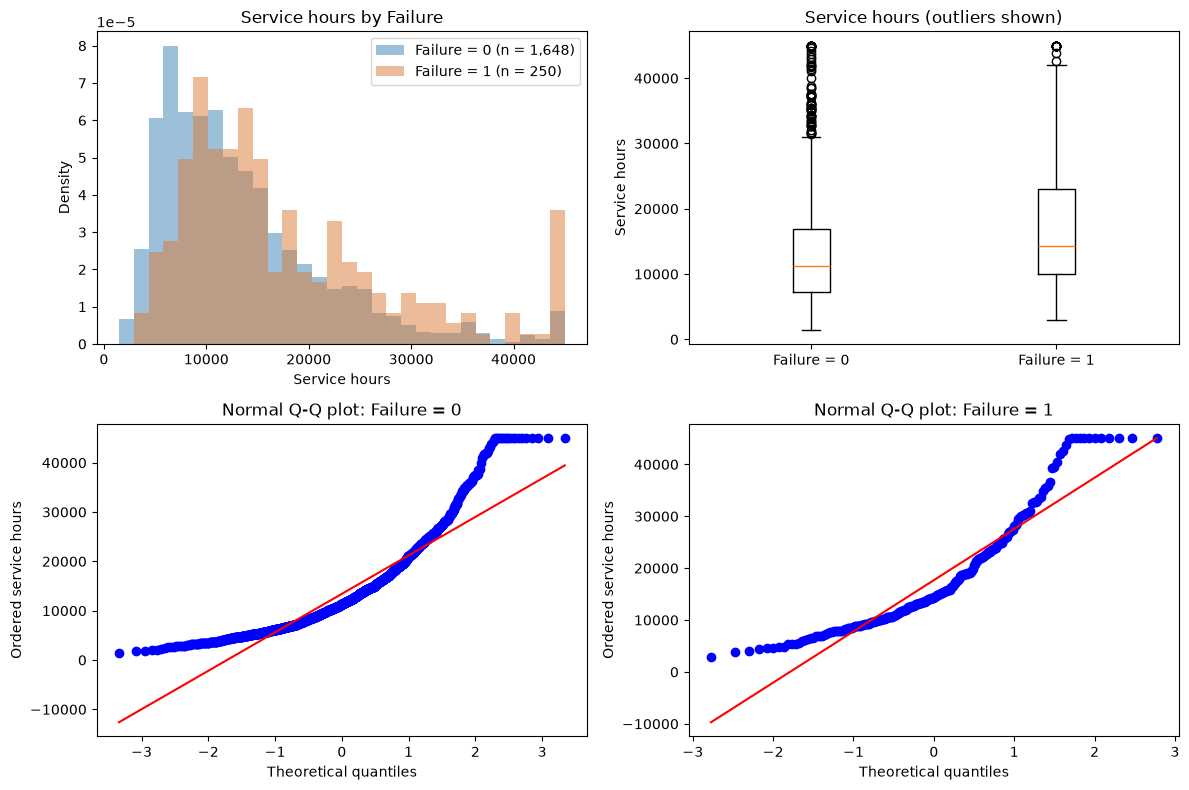

In [302]:
ALPHA = 0.05
assert h1_data["unit_key"].is_unique
assert h1_data["Failure"].isin([0, 1]).all()
assert h1_data["serviceHours"].notna().all()
assert np.isfinite(h1_data["serviceHours"]).all()
service_groups = {
    label: h1_data.loc[h1_data["Failure"].eq(label), "serviceHours"].to_numpy()
    for label in (0, 1)
}
print(f"Unavailable serviceHours excluded after unit sampling: {len(analysis_units) - len(h1_data)}")
service_summary = h1_data.groupby("Failure")["serviceHours"].describe(
    percentiles=[0.05, 0.25, 0.5, 0.75, 0.95]
)
service_summary["skewness"] = h1_data.groupby("Failure")["serviceHours"].skew()
display(service_summary.round(2))

# Describe IQR outliers without excluding them from the analysis
outlier_rows = []
normality_rows = []
for label, values in service_groups.items():
    q1, q3 = np.quantile(values, [0.25, 0.75])
    lower, upper = q1 - 1.5 * (q3 - q1), q3 + 1.5 * (q3 - q1)
    flagged = (values < lower) | (values > upper)
    outlier_rows.append({"Failure": label, "lower_fence": lower,
        "upper_fence": upper, "IQR_outliers": flagged.sum(),
        "outlier_percent": 100 * flagged.mean()})
    # Both groups have fewer than 5,000 observations, so use the full samples
    result = stats.shapiro(values)
    normality_rows.append({"Failure": label, "n": len(values),
        "Shapiro_W": result.statistic, "p_value": result.pvalue})
print("IQR diagnostic only; flagged observations are retained:")
display(pd.DataFrame(outlier_rows).set_index("Failure").round(2))
print("Shapiro-Wilk normality diagnostic:")
display(pd.DataFrame(normality_rows).set_index("Failure"))
levene_result = stats.levene(service_groups[0], service_groups[1], center="median")
print(f"Median-centered Levene test: W = {levene_result.statistic:.4f}, "
      f"p = {levene_result.pvalue:.6g}")

fig, axes = plt.subplots(2, 2, figsize=(12, 8))
bins = np.histogram_bin_edges(h1_data["serviceHours"], bins=30)
for label, color in zip((0, 1), ("#3B82B6", "#D97936")):
    axes[0, 0].hist(service_groups[label], bins=bins, density=True, alpha=0.5,
                    color=color, label=f"Failure = {label} (n = {len(service_groups[label]):,})")
    stats.probplot(service_groups[label], dist="norm", plot=axes[1, label])
    axes[1, label].set_title(f"Normal Q-Q plot: Failure = {label}")
    axes[1, label].set_ylabel("Ordered service hours")
axes[0, 0].set(title="Service hours by Failure", xlabel="Service hours", ylabel="Density")
axes[0, 0].legend()
axes[0, 1].boxplot([service_groups[0], service_groups[1]], showfliers=True)
axes[0, 1].set_xticks([1, 2], labels=["Failure = 0", "Failure = 1"])
axes[0, 1].set(title="Service hours (outliers shown)", ylabel="Service hours")
fig.tight_layout()
plt.show()

#### Assumptions and test choice

Both groups are right-skewed (skewness 1.49 for Failure = 0 and 1.15 for Failure = 1).
Q-Q plots and Shapiro-Wilk indicate non-normality. Median-centered Levene gives
p = 0.0000604, suggesting unequal spread. These are assumption checks, not extra
research hypotheses; normality tests are sensitive with large samples.

We choose **two-sided Mann-Whitney U** to compare ranks in these skewed
distributions. The large samples support its asymptotic calculation with tie and
continuity corrections. Welch's test would instead address mean differences.

Mann-Whitney is **not necessarily a test of medians**, especially with unequal
spreads, and cannot detect every distributional difference. Effect size
A = U1/(n1*n0) estimates P(X1 > X0) plus half the tie probability. A = 0.5 means
no rank advantage; rank-biserial effect = 2A - 1. Bootstrap intervals describe
uncertainty in A.

In [303]:
x1, x0 = service_groups[1], service_groups[0]
h1_result = stats.mannwhitneyu(
    x1, x0, alternative="two-sided", method="asymptotic", use_continuity=True
)
superiority = h1_result.statistic / (len(x1) * len(x0))
rank_biserial = 2 * superiority - 1

# Resample units within each group; this is not a power calculation
bootstrap_rng = np.random.default_rng(134)
bootstrap_a = np.empty(2000)
for i in range(len(bootstrap_a)):
    sample1 = bootstrap_rng.choice(x1, size=len(x1), replace=True)
    sample0 = bootstrap_rng.choice(x0, size=len(x0), replace=True)
    bootstrap_a[i] = stats.mannwhitneyu(
        sample1, sample0, alternative="two-sided", method="asymptotic"
    ).statistic / (len(x1) * len(x0))
superiority_ci = np.quantile(bootstrap_a, [0.025, 0.975])
display(pd.DataFrame([{
    "test": "Mann-Whitney U (two-sided)", "n0": len(x0), "n1": len(x1),
    "U1": h1_result.statistic, "p_value": h1_result.pvalue, "alpha": ALPHA,
    "probability_superiority_A": superiority, "rank_biserial": rank_biserial,
    "A_95CI_lower": superiority_ci[0], "A_95CI_upper": superiority_ci[1],
}]))
display(Markdown(
    f"**Interpretation:** U1 = {h1_result.statistic:,.0f}, "
    f"p = {h1_result.pvalue:.3g}. At alpha = {ALPHA}, "
    f"{'reject' if h1_result.pvalue < ALPHA else 'do not reject'} H0. "
    f"A = {superiority:.3f} (95% bootstrap interval "
    f"{superiority_ci[0]:.3f} to {superiority_ci[1]:.3f}); "
    f"rank-biserial effect = {rank_biserial:.3f}. "
    f"For a random pair of observed units from these groups, the estimated "
    f"probability that the failure-labelled unit has higher service hours, "
    f"counting ties as half, is {100 * superiority:.1f}%. "
    f"The medians are {np.median(x1):,.2f} versus {np.median(x0):,.2f} hours "
    f"(Failure 1 versus 0), but the test does not establish a median-only difference. "
    f"There is rank separation with substantial overlap, not perfect class separation."
))

,test,n0,n1,U1,p_value,alpha,probability_superiority_A,rank_biserial,A_95CI_lower,A_95CI_upper
0,Mann-Whitney U (two-sided),1648,250,260706.0,1.243805e-11,0.05,0.632782,0.265563,0.598232,0.669452


**Interpretation:** U1 = 260,706, p = 1.24e-11. At alpha = 0.05, reject H0. A = 0.633 (95% bootstrap interval 0.598 to 0.669); rank-biserial effect = 0.266. For a random pair of observed units from these groups, the estimated probability that the failure-labelled unit has higher service hours, counting ties as half, is 63.3%. The medians are 14,345.35 versus 11,297.60 hours (Failure 1 versus 0), but the test does not establish a median-only difference. There is rank separation with substantial overlap, not perfect class separation.

U = **260,706**, p = **1.24e-11**: reject H0 at alpha = 0.05.
A = **0.633** (95% bootstrap interval 0.598-0.669), with rank-biserial effect
**0.266**. Failure-labelled units tend to have higher service hours, but the
distributions overlap. Their median is 14,345.35 versus 11,297.60 hours.

This association does not show causality or future predictive usefulness. Missing
metadata may bias the comparison, and service hours may have been recorded later.
The interval applies to the fixed selected readings, not alternative selections.

### 1.3(A2) - Hypothesis 2: Missing FilterDp and Failure

**Question:** Is filterDp missingness associated with Failure?

- **H0:** Missingness of filterDp and Failure are independent.
- **H1:** Missingness of filterDp and Failure are associated.

Use alpha = 0.05 and all **2,117 selected units**. The indicator uses original
measurement availability before imputation. Missing filterDp values and unmatched
metadata do not exclude units from this test.

Observed counts:


,filterDp observed,filterDp missing
Failure,,
0,1811,33
1,215,58


,units,missing_count,missing_percent
Failure,,,
0,1844,33,1.79
1,273,58,21.25


Expected counts under independence:


,filterDp observed,filterDp missing
Failure,,
0,1764.74,79.26
1,261.26,11.74


Minimum expected count: 11.74; all four cells >= 5.


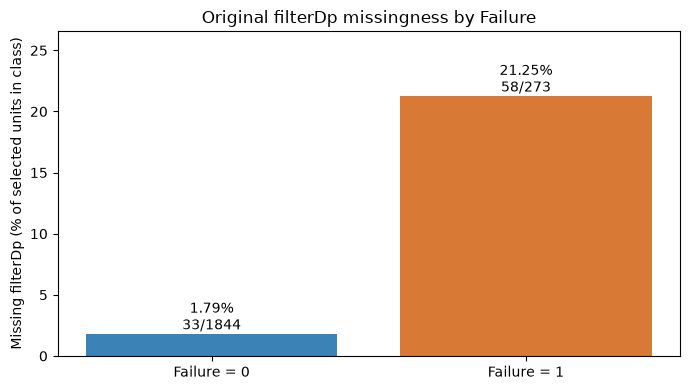

In [304]:
assert h2_data["unit_key"].is_unique
assert h2_data["Failure"].isin([0, 1]).all()
# Verify availability against the original readings, not a filled measurement
original_filter = readings_raw.loc[h2_data["reading_row_id"], "filterDp"].reset_index(drop=True)
assert np.array_equal(h2_data["filterDp"].isna(), original_filter.isna())
assert np.array_equal(h2_data["filterDp_missing"], original_filter.isna())
missing_table = pd.crosstab(h2_data["Failure"], h2_data["filterDp_missing"]).reindex(
    index=[0, 1], columns=[False, True], fill_value=0
)
missing_table.columns = ["filterDp observed", "filterDp missing"]
assert missing_table.to_numpy().sum() == len(h2_data)
print("Observed counts:")
display(missing_table)
missing_percent = 100 * missing_table["filterDp missing"] / missing_table.sum(axis=1)
display(pd.DataFrame({"units": missing_table.sum(axis=1),
    "missing_count": missing_table["filterDp missing"],
    "missing_percent": missing_percent}).round(2))

# Pearson test without Yates correction; all expected cells must be at least 5
chi2_stat, chi2_p, chi2_df, expected = stats.chi2_contingency(
    missing_table.to_numpy(), correction=False
)
expected_table = pd.DataFrame(expected, index=missing_table.index, columns=missing_table.columns)
print("Expected counts under independence:")
display(expected_table.round(2))
assert (expected >= 5).all(), "Use an exact alternative for sparse expected counts."
print(f"Minimum expected count: {expected.min():.2f}; all four cells >= 5.")

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.bar([0, 1], missing_percent.to_numpy(), color=["#3B82B6", "#D97936"])
ax.set_xticks([0, 1], labels=["Failure = 0", "Failure = 1"])
ax.set_ylabel("Missing filterDp (% of selected units in class)")
ax.set_title("Original filterDp missingness by Failure")
ax.set_ylim(0, max(missing_percent) * 1.25)
for bar, percent, label in zip(bars, missing_percent, [0, 1]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
        f"{percent:.2f}%\n{missing_table.loc[label, 'filterDp missing']}/{missing_table.loc[label].sum()}",
        ha="center", va="bottom")
fig.tight_layout()
plt.show()

#### Assumptions and test choice

Use **Pearson chi-square** with 1 degree of freedom and no Yates correction.
Each unit contributes once. All expected counts exceed 5 (minimum 11.74), so the
chi-square approximation is suitable. Independence between units is still assumed;
testing all repeated readings would break this design.

The **odds ratio** compares the odds of missing filterDp in Failure = 1 versus
Failure = 0; 1 means no odds association. It is not a probability ratio. We report
a log-scale 95% interval, with no zero-cell correction needed. Cramer's V measures
the strength of association without its direction.

In [305]:
observed0, missing0 = missing_table.loc[0].to_numpy()
observed1, missing1 = missing_table.loc[1].to_numpy()
assert min(observed0, missing0, observed1, missing1) > 0
odds_ratio = (missing1 * observed0) / (observed1 * missing0)
log_or_se = np.sqrt(1/missing1 + 1/observed1 + 1/missing0 + 1/observed0)
odds_ratio_ci = np.exp(np.log(odds_ratio) + np.array([-1, 1]) * stats.norm.ppf(0.975) * log_or_se)
cramers_v = np.sqrt(chi2_stat / missing_table.to_numpy().sum())
display(pd.DataFrame([{
    "test": "Pearson chi-square", "chi2": chi2_stat, "df": chi2_df,
    "p_value": chi2_p, "alpha": ALPHA, "odds_ratio": odds_ratio,
    "OR_95CI_lower": odds_ratio_ci[0], "OR_95CI_upper": odds_ratio_ci[1],
    "Cramers_V": cramers_v,
}]))
display(Markdown(
    f"**Interpretation:** chi-square({chi2_df}) = {chi2_stat:.3f}, "
    f"p = {chi2_p:.3g}. At alpha = {ALPHA}, "
    f"{'reject' if chi2_p < ALPHA else 'do not reject'} H0. "
    f"Missingness is {missing_percent.loc[1]:.2f}% in Failure = 1 versus "
    f"{missing_percent.loc[0]:.2f}% in Failure = 0. "
    f"The estimated odds of missing filterDp are {odds_ratio:.2f} times as high "
    f"in the failure-labelled group (95% CI {odds_ratio_ci[0]:.2f} to "
    f"{odds_ratio_ci[1]:.2f}); Cramer's V = {cramers_v:.3f}. "
    f"The odds ratio is not a ratio of probabilities. "
    f"The observed percentage difference and effect sizes describe the association; "
    f"its operational usefulness cannot be inferred from significance alone."
))

# Holm adjustment for the two primary research tests, excluding diagnostics
primary_results = pd.DataFrame({
    "hypothesis": ["H1: serviceHours", "H2: filterDp missingness"],
    "p_value": [h1_result.pvalue, chi2_p],
}).sort_values("p_value")
primary_results["Holm_adjusted_p"] = np.minimum(
    1, np.maximum.accumulate(primary_results["p_value"].to_numpy() * np.array([2, 1]))
)
primary_results["reject_at_family_alpha_0.05"] = primary_results["Holm_adjusted_p"] < ALPHA
print("Two primary hypotheses: Holm family-wise adjustment")
display(primary_results.sort_index().reset_index(drop=True))

,test,chi2,df,p_value,alpha,odds_ratio,OR_95CI_lower,OR_95CI_upper,Cramers_V
0,Pearson chi-square,218.808035,1,1.645829e-49,0.05,14.80451,9.438427,23.221404,0.321493


**Interpretation:** chi-square(1) = 218.808, p = 1.65e-49. At alpha = 0.05, reject H0. Missingness is 21.25% in Failure = 1 versus 1.79% in Failure = 0. The estimated odds of missing filterDp are 14.80 times as high in the failure-labelled group (95% CI 9.44 to 23.22); Cramer's V = 0.321. The odds ratio is not a ratio of probabilities. The observed percentage difference and effect sizes describe the association; its operational usefulness cannot be inferred from significance alone.

Two primary hypotheses: Holm family-wise adjustment


,hypothesis,p_value,Holm_adjusted_p,reject_at_family_alpha_0.05
0,H1: serviceHours,1.243805e-11,1.243805e-11,True
1,H2: filterDp missingness,1.645829e-49,3.291658e-49,True


Chi-square(1) = **218.808**, p = **1.65e-49**: reject H0 at alpha = 0.05.
Missingness is **21.25% versus 1.79%** (Failure 1 versus 0). The odds ratio is
**14.80** (95% CI 9.44-23.22), and Cramer's V is **0.321**.

Missingness may reflect reporting or failure-recording procedures; its timing is
unknown, so this is not evidence of causality or advance prediction.

Both research tests remain significant after **Holm correction** at family
alpha = 0.05. Effect intervals are individual, not simultaneous intervals.
Significance alone does not show practical importance or sufficient power.

### 1.3(B) - Statistical Power Analysis

#### Definitions and planning assumptions

**Power** is the probability of rejecting H0 when a stated alternative is true.
We target **0.80**. A Type I error rejects a true H0; **alpha = 0.05** controls
its probability under the test assumptions. A Type II error misses an effect;
its probability is beta, with power = 1 - beta.

Use the actual independent samples: H1 has 1,648 non-failure and 250 failure
units; H2 has 1,844 and 273. Sample-size scenarios keep these allocation ratios
(n1/n0), with rounding. H1 sizes mean units with available service hours.

These are **illustrative planning effects**, not measured effects or validated
practical thresholds:

- H1: **A = 0.60**, equivalent to rank-biserial effect **0.20**.
- H2: missingness **2% versus 7%**, a **5-percentage-point increase**. The 2%
  baseline is a rounded assumption informed by the non-failure group.

We assess alpha = 0.05 and conservative **0.025**, sufficient for Holm rejection
with two tests. This does not estimate the probability of rejecting both together.
Power depends on the assumed effect and model; observed-effect post-hoc power
would not independently validate the tests.

#### Simulation methods

**H1:** Generate independent lognormal samples with equal shape and a log-scale
shift chosen to give the specified A. Apply the same two-sided Mann-Whitney test
as above. This is an illustrative model, not a fit to the observed unequal spreads;
power may differ for other shapes or rounded-value ties.

**H2:** Generate missing counts from binomial distributions using the group sizes
and assumed missingness rates. Apply the same uncorrected Pearson chi-square test.
The output also reports the assumed odds ratio and Cohen's w; for this 2-by-2
table, w equals population Cramer's V and depends on allocation and baseline rate.

Use fixed seeds, **2,000 H1 simulations** and **20,000 H2 simulations** per scenario.
Standard errors and 95% Wilson intervals show simulation uncertainty. Null
scenarios check rejection rates; sparse chi-square tables are reported, not dropped.

Search effects in steps of **0.01 for A** and **0.005 for the missingness increase**.
A grid point qualifies when its lower simulation interval reaches 0.80. Sample-size
searches also require planned H2 expected cells of at least 5. These are supported
grid thresholds, not exact minima.


In [306]:
TARGET_POWER = 0.80
POWER_ALPHAS = (ALPHA, ALPHA / 2)
MW_REPETITIONS = 2000
CHI_REPETITIONS = 20000
ASSUMED_A = 0.60
ASSUMED_P0 = 0.02
ASSUMED_RATE_INCREASE = 0.05

n0_h1, n1_h1 = len(service_groups[0]), len(service_groups[1])
h2_sizes = h2_data.groupby("Failure").size()
n0_h2, n1_h2 = int(h2_sizes.loc[0]), int(h2_sizes.loc[1])
assert n0_h1 + n1_h1 == len(h1_data) == h1_data["unit_key"].nunique()
assert n0_h2 + n1_h2 == len(h2_data) == h2_data["unit_key"].nunique()
allocations = pd.DataFrame([
    {"hypothesis": "H1", "n0": n0_h1, "n1": n1_h1},
    {"hypothesis": "H2", "n0": n0_h2, "n1": n1_h2},
]).set_index("hypothesis")
allocations["N"] = allocations["n0"] + allocations["n1"]
allocations["allocation_n1_over_n0"] = allocations["n1"] / allocations["n0"]
display(allocations.round(4))

def rejection_summary(pvalues, alpha):
    count, repetitions = int(np.sum(pvalues < alpha)), len(pvalues)
    estimate = count / repetitions
    z = stats.norm.ppf(0.975)
    denominator = 1 + z*z / repetitions
    center = (estimate + z*z/(2*repetitions)) / denominator
    half = z * np.sqrt(estimate*(1-estimate)/repetitions + z*z/(4*repetitions**2)) / denominator
    return {"power": estimate, "MC_SE": np.sqrt(estimate*(1-estimate)/repetitions),
            "MC_95_low": max(0, center-half), "MC_95_high": min(1, center+half)}

def simulate_mw(n0, n1, a, seed):
    rng = np.random.default_rng(seed)
    shift = np.sqrt(2) * stats.norm.ppf(a)
    pvalues = np.empty(MW_REPETITIONS)
    # Batches keep memory use small; observations represent different units.
    for first in range(0, MW_REPETITIONS, 100):
        size = min(100, MW_REPETITIONS-first)
        group0 = np.exp(rng.normal(size=(size, n0)))
        group1 = np.exp(rng.normal(size=(size, n1)) + shift)
        pvalues[first:first+size] = stats.mannwhitneyu(
            group1, group0, axis=1, alternative="two-sided",
            method="asymptotic", use_continuity=True,
        ).pvalue
    return [{"alpha": alpha, **rejection_summary(pvalues, alpha)} for alpha in POWER_ALPHAS]

def planned_binary_effect(n0, n1, p0, p1):
    allocation = np.array([n0, n1]) / (n0+n1)
    joint = allocation[:, None] * np.array([[1-p0, p0], [1-p1, p1]])
    independent = np.outer(allocation, joint.sum(axis=0))
    w = np.sqrt(np.sum((joint-independent)**2 / independent))
    odds = (p1/(1-p1)) / (p0/(1-p0))
    return w, odds, float(((n0+n1)*independent).min())

def simulate_chi(n0, n1, p0, p1, seed):
    rng = np.random.default_rng(seed)
    missing0 = rng.binomial(n0, p0, size=CHI_REPETITIONS)
    missing1 = rng.binomial(n1, p1, size=CHI_REPETITIONS)
    missing_total = missing0 + missing1
    total = n0+n1
    denominator = n0 * n1 * missing_total.astype(float) * (total-missing_total)
    numerator = total * (missing1*n0 - missing0*n1).astype(float)**2
    # An all-observed/all-missing table contains no availability contrast.
    chi_stat = np.divide(numerator, denominator, out=np.zeros(CHI_REPETITIONS), where=denominator>0)
    pvalues = stats.chi2.sf(chi_stat, df=1)
    expected_min = np.minimum(n0, n1) * np.minimum(missing_total, total-missing_total) / total
    w, odds, planned_min = planned_binary_effect(n0, n1, p0, p1)
    return [{"alpha": alpha, **rejection_summary(pvalues, alpha),
             "Cohen_w": w, "assumed_OR": odds, "planned_min_expected": planned_min,
             "simulated_sparse_percent": 100*np.mean(expected_min < 5)}
            for alpha in POWER_ALPHAS]

# Algebra check: the vectorized statistic matches the original Pearson test
check_counts = missing_table.to_numpy()
a0, b0 = check_counts[0]
a1, b1 = check_counts[1]
check_stat = check_counts.sum() * float(b1*a0-b0*a1)**2 / (
    (a0+b0)*(a1+b1)*(b0+b1)*(a0+a1)
)
assert np.isclose(check_stat, chi2_stat)

mw_effect_rows = []
for i, a in enumerate(np.round(np.arange(0.50, 0.651, 0.01), 2)):
    for result in simulate_mw(n0_h1, n1_h1, a, seed=5100+i):
        mw_effect_rows.append({"A": a, "rank_biserial": 2*a-1, **result})
mw_sensitivity = pd.DataFrame(mw_effect_rows)
chi_effect_rows = []
for i, increase in enumerate(np.round(np.arange(0, 0.0801, 0.005), 3)):
    for result in simulate_chi(n0_h2, n1_h2, ASSUMED_P0, ASSUMED_P0+increase, seed=5200+i):
        chi_effect_rows.append({"rate_increase": increase, "p0": ASSUMED_P0,
                                "p1": ASSUMED_P0+increase, **result})
chi_sensitivity = pd.DataFrame(chi_effect_rows)
print("Null calibration: rejection probability should be near the stated alpha.")
display(pd.concat([
    mw_sensitivity.loc[mw_sensitivity["A"].eq(0.5)].assign(test="Mann-Whitney"),
    chi_sensitivity.loc[chi_sensitivity["rate_increase"].eq(0)].assign(test="Pearson chi-square"),
], ignore_index=True)[["test", "alpha", "power", "MC_SE", "MC_95_low", "MC_95_high"]])

,n0,n1,N,allocation_n1_over_n0
hypothesis,,,,
H1,1648,250,1898,0.1517
H2,1844,273,2117,0.1480


Null calibration: rejection probability should be near the stated alpha.


,test,alpha,power,MC_SE,MC_95_low,MC_95_high
0,Mann-Whitney,0.050,0.0460,0.004684,0.037657,0.056084
1,Mann-Whitney,0.025,0.0230,0.003352,0.017288,0.030541
2,Pearson chi-square,0.050,0.0498,0.001538,0.046871,0.052902
3,Pearson chi-square,0.025,0.0257,0.001119,0.023596,0.027986


Summary: H1 effects are A; H2 effects are absolute missingness-rate increases.


,hypothesis,alpha,N available,Detectable effect (grid),Benchmark power (95% MC interval),N required (grid),Sufficient for assumed effect
0,H1,0.050,1898,0.560,1.000 (0.997-1.000),750,True
1,H2,0.050,2117,0.035,0.978 (0.976-0.980),1500,True
2,H1,0.025,1898,0.570,0.998 (0.995-0.999),750,True
3,H2,0.025,2117,0.035,0.966 (0.963-0.968),1500,True


H2 assumed effect and sparse-table diagnostic at available N:


,alpha,p0,p1,assumed_OR,Cohen_w,planned_min_expected,simulated_sparse_percent
20,0.050,0.02,0.07,3.6882,0.1044,7.2203,0.62
21,0.025,0.02,0.07,3.6882,0.1044,7.2203,0.62


Independent sample-size grids evaluated (minimum adequate grid point, not exact minimum):
H1: [500, 750, 1000, 1250, 1500, 1750, 1898, 2250, 2500, 3000]
H2: [500, 750, 1000, 1250, 1500, 1750, 2000, 2117, 2500, 3000, 4000]


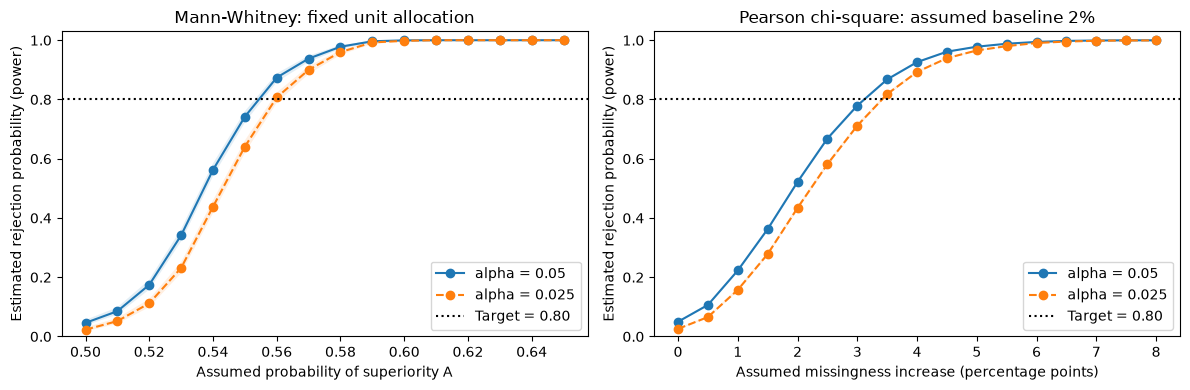

In [307]:
def allocated_counts(total, n0, n1):
    new_n1 = int(round(total*n1/(n0+n1)))
    return total-new_n1, new_n1

mw_size_rows, chi_size_rows = [], []
# These are planned independent, analysable unit counts, not sensor row counts
mw_size_grid = sorted(set([500, 750, 1000, 1250, 1500, 1750, len(h1_data), 2250, 2500, 3000]))
chi_size_grid = sorted(set([500, 750, 1000, 1250, 1500, 1750, 2000, len(h2_data), 2500, 3000, 4000]))
for i, total in enumerate(mw_size_grid):
    new_n0, new_n1 = allocated_counts(total, n0_h1, n1_h1)
    # Reuse the existing simulation at the available N
    results = (mw_sensitivity.loc[np.isclose(mw_sensitivity["A"], ASSUMED_A)].to_dict("records")
               if total == len(h1_data) else simulate_mw(new_n0, new_n1, ASSUMED_A, 5300+i))
    for result in results:
        mw_size_rows.append({**result, "N": total, "n0": new_n0, "n1": new_n1})
for i, total in enumerate(chi_size_grid):
    new_n0, new_n1 = allocated_counts(total, n0_h2, n1_h2)
    results = (chi_sensitivity.loc[np.isclose(chi_sensitivity["rate_increase"], ASSUMED_RATE_INCREASE)].to_dict("records")
               if total == len(h2_data) else simulate_chi(
                   new_n0, new_n1, ASSUMED_P0, ASSUMED_P0+ASSUMED_RATE_INCREASE, 5400+i))
    for result in results:
        chi_size_rows.append({**result, "N": total, "n0": new_n0, "n1": new_n1})
mw_sample_planning = pd.DataFrame(mw_size_rows)
chi_sample_planning = pd.DataFrame(chi_size_rows)

summary_rows = []
for alpha in POWER_ALPHAS:
    mw_effects = mw_sensitivity.loc[mw_sensitivity["alpha"].eq(alpha)]
    chi_effects = chi_sensitivity.loc[chi_sensitivity["alpha"].eq(alpha)]
    minimum_a = mw_effects.loc[mw_effects["MC_95_low"].ge(TARGET_POWER)].iloc[0]
    minimum_increase = chi_effects.loc[
        chi_effects["MC_95_low"].ge(TARGET_POWER) & chi_effects["planned_min_expected"].ge(5)
    ].iloc[0]
    for hypothesis, effects, planning, benchmark, minimum, effect_column, available, n0, n1 in [
        ("H1", mw_effects, mw_sample_planning, ASSUMED_A, minimum_a, "A", len(h1_data), n0_h1, n1_h1),
        ("H2", chi_effects, chi_sample_planning, ASSUMED_RATE_INCREASE, minimum_increase,
         "rate_increase", len(h2_data), n0_h2, n1_h2),
    ]:
        at_benchmark = effects.loc[np.isclose(effects[effect_column], benchmark)].iloc[0]
        candidates = planning.loc[planning["alpha"].eq(alpha) & planning["MC_95_low"].ge(TARGET_POWER)]
        if hypothesis == "H2":
            candidates = candidates.loc[candidates["planned_min_expected"].ge(5)]
        required = candidates.sort_values("N").iloc[0]
        summary_rows.append({
            "hypothesis": hypothesis, "alpha": alpha, "target_power": TARGET_POWER,
            "available_N": available, "n0": n0, "n1": n1, "n1/n0": n1/n0,
            "assumed_benchmark": benchmark, "grid_detectable_effect": minimum[effect_column],
            "benchmark_power": at_benchmark["power"],
            "power_MC95_low": at_benchmark["MC_95_low"], "power_MC95_high": at_benchmark["MC_95_high"],
            "required_N_on_grid": int(required["N"]),
            "required_n0": int(required["n0"]), "required_n1": int(required["n1"]),
            "sufficient_for_assumed_effect": bool(at_benchmark["MC_95_low"] >= TARGET_POWER),
        })
power_summary = pd.DataFrame(summary_rows)
print("Summary: H1 effects are A; H2 effects are absolute missingness-rate increases.")
compact_power_summary = power_summary[[
    "hypothesis", "alpha", "available_N", "grid_detectable_effect",
    "benchmark_power", "required_N_on_grid", "sufficient_for_assumed_effect",
]].copy()
compact_power_summary["benchmark_power"] = [
    f"{r.benchmark_power:.3f} ({r.power_MC95_low:.3f}-{r.power_MC95_high:.3f})"
    for r in power_summary.itertuples()
]
compact_power_summary = compact_power_summary.rename(columns={
    "available_N": "N available", "grid_detectable_effect": "Detectable effect (grid)",
    "benchmark_power": "Benchmark power (95% MC interval)",
    "required_N_on_grid": "N required (grid)",
    "sufficient_for_assumed_effect": "Sufficient for assumed effect",
})
display(compact_power_summary)
print("H2 assumed effect and sparse-table diagnostic at available N:")
display(chi_sensitivity.loc[np.isclose(chi_sensitivity["rate_increase"], ASSUMED_RATE_INCREASE),
    ["alpha", "p0", "p1", "assumed_OR", "Cohen_w", "planned_min_expected", "simulated_sparse_percent"]].round(4))
print("Independent sample-size grids evaluated (minimum adequate grid point, not exact minimum):")
print("H1:", mw_size_grid)
print("H2:", chi_size_grid)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
for alpha, style in zip(POWER_ALPHAS, ("-", "--")):
    for ax, table, effect, multiplier in [
        (axes[0], mw_sensitivity, "A", 1),
        (axes[1], chi_sensitivity, "rate_increase", 100),
    ]:
        rows = table.loc[table["alpha"].eq(alpha)]
        grid = multiplier*rows[effect].to_numpy()
        ax.plot(grid, rows["power"], style, marker="o", label=f"alpha = {alpha}")
        ax.fill_between(grid, rows["MC_95_low"], rows["MC_95_high"], alpha=0.12)
for ax in axes:
    ax.axhline(TARGET_POWER, color="black", linestyle=":", label="Target = 0.80")
    ax.set_ylabel("Estimated rejection probability (power)")
    ax.set_ylim(0, 1.03)
    ax.legend()
axes[0].set(title="Mann-Whitney: fixed unit allocation", xlabel="Assumed probability of superiority A")
axes[1].set(title="Pearson chi-square: assumed baseline 2%", xlabel="Assumed missingness increase (percentage points)")
fig.tight_layout()
plt.show()

In [308]:
for hypothesis in ("H1", "H2"):
    row = power_summary.loc[power_summary["hypothesis"].eq(hypothesis)
                            & power_summary["alpha"].eq(ALPHA/2)].iloc[0]
    effect_description = (f"A = {row['grid_detectable_effect']:.2f} "
                          f"(rank-biserial {2*row['grid_detectable_effect']-1:.2f})"
                          if hypothesis == "H1" else
                          f"a {100*row['grid_detectable_effect']:.1f}-percentage-point increase "
                          f"from the assumed 2% baseline")
    display(Markdown(
        f"**{hypothesis}:** At the conservative alpha = 0.025, the smallest supported "
        f"effect on our grid is {effect_description}. For the illustrative benchmark, "
        f"estimated power is {row['benchmark_power']:.3f} (simulation 95% interval "
        f"{row['power_MC95_low']:.3f} to {row['power_MC95_high']:.3f}). "
        f"The available {int(row['available_N']):,} independent units "
        f"{'are sufficient' if row['sufficient_for_assumed_effect'] else 'are not sufficient'} "
        f"for this assumed effect under the simulation model. The first adequate "
        f"sample-size grid point is {int(row['required_N_on_grid']):,} analysable units "
        f"(n0 = {int(row['required_n0']):,}, n1 = {int(row['required_n1']):,})."
    ))

**H1:** At the conservative alpha = 0.025, the smallest supported effect on our grid is A = 0.57 (rank-biserial 0.14). For the illustrative benchmark, estimated power is 0.998 (simulation 95% interval 0.995 to 0.999). The available 1,898 independent units are sufficient for this assumed effect under the simulation model. The first adequate sample-size grid point is 750 analysable units (n0 = 651, n1 = 99).

**H2:** At the conservative alpha = 0.025, the smallest supported effect on our grid is a 3.5-percentage-point increase from the assumed 2% baseline. For the illustrative benchmark, estimated power is 0.966 (simulation 95% interval 0.963 to 0.968). The available 2,117 independent units are sufficient for this assumed effect under the simulation model. The first adequate sample-size grid point is 1,500 analysable units (n0 = 1,307, n1 = 193).

#### Assessment and limitations

At conservative alpha = 0.025, power is **0.998 for H1** and **0.966 for H2** under
the assumed benchmarks. Both available samples are sufficient for these effects.
The first adequate sample-size grid points are **750 units for H1** and **1,500
for H2**, compared with 1,898 and 2,117 available.

Supported effect thresholds are **A = 0.57** and a **3.5-percentage-point increase**
from 2% missingness. Smaller effects may be missed. Results depend on the simulation
models and assume independent units. Shared conditions, missing metadata and the
fixed reading selection remain limitations; the benchmarks need domain judgement.

### 1.3 - Statistical Conclusions

Both hypotheses show associations with Failure and remain significant after Holm
correction. Service hours tend to be higher for failure-labelled units; filterDp
is more often missing in that group. Neither result establishes causality or
advance prediction.

Power exceeds 0.80 for the stated illustrative effects, but this does not guarantee
adequate power for smaller effects or other distribution shapes.

For later ML phases, investigate serviceHours and filterDp availability while
checking that they exist before prediction time. Define the prediction horizon,
split evaluation data by unit and reliable time order, and fit preprocessing on
training data only. Missing metadata, unresolved dates and information lost by
sampling remain limitations. Predictive usefulness must be checked on held-out
data, not inferred from p-values alone.

## Overall Phase 1 Conclusions and Preparation for Phase 2

**What we learned.** Raw EDA covered eight sensors plus commission_year and
serviceHours. Sensor rank correlations are close to zero, while Failure groups
show differences in several sensor distributions and metadata. These descriptive
patterns are candidates for investigation, not evidence of causation.

**Data preparation decision.** Removing 196 exact copies leaves 13,092 readings.
The LEFT JOIN retains all of them, including 131 without matching unit metadata.
The integrated baseline keeps original labels and missingness. IQR removal
excludes a larger proportion of failure readings; clipping changes available
measurements. Both remain comparison alternatives rather than the working
dataset for hypothesis testing.

**Statistical evidence.** Both unit-level comparisons remain significant after
Holm correction. Service hours show rank separation, and filterDp availability
is associated with Failure. Effect sizes and overlapping distributions matter
as well as significance. Power exceeds 0.80 for the explicit illustrative
benchmarks, with limitations for smaller effects, other distribution shapes
and dependence between units.

**Next steps for Phase 2.**

- Resolve ambiguous dates, commissioning inconsistencies and metadata timing
  where possible; retain flags when the correct values are unknown.
- Define the prediction horizon and check that measurements, service hours and
  availability indicators exist before the prediction time to avoid leakage.
- Split evaluation data by unit and use reliable time ordering where needed.
  Fit imputation, scaling, transformations and outlier thresholds on training
  data only; assess missingness indicators and compare preparation choices.
- Evaluate predictive usefulness on held-out data while accounting for class
  imbalance and repeated measurements. Exploratory p-values alone do not select
  a final feature set or demonstrate future failure prediction.
